## Pontificia Universidad Javeriana

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSD1Tsz-TGSmWtmI0NCrivhX8pcljNrvDgMETaY1n7WAMQ_AwTbCAwjKIR0&s=10" alt="drawing" width="200"/>

# Procesamiento de Datos a Gran Escala

# Modelos de Clasificación: Modelo de Detección de Salarios

### Fecha: 24 de noviembre de 2026

### Autor: Lorenzo Ramirez Calderon (ID: 20550074)

### Docente: John Jairo Corredor



## **Contexto**

El conjunto de datos **Adult Census Income**, obtenido del repositorio UCI Machine Learning Repository, contiene información demográfica, educativa, laboral y económica de individuos, extraída de una base de datos censal de Estados Unidos de 1994.

El objetivo del conjunto de datos es predecir si los ingresos anuales de un individuo superan los 50.000 dólares a partir de sus características personales y socioeconómicas. Por lo tanto, se aborda un problema de aprendizaje supervisado de clasificación binaria.

En este contexto, las técnicas de aprendizaje automático permiten identificar patrones y relaciones presentes en grandes volúmenes de datos, con el propósito de construir modelos capaces de realizar predicciones sobre observaciones socioeconómicas de los individuos.

El conjunto de datos presenta las siguientes características:

| Característica | Descripción |
|---|---|
| Nombre | Adult Census Income |
| Año de los datos | 1994 |
| Número de registros | 48.842 |
| Número de atributos predictivos | 14 |
| Número total de columnas | 15 |
| Variable objetivo | `income` |

## **Objetivos**
- Aplicar la metodología CRISP-DM al conjunto de datos Adult Census Income.

- Caracterizar el conjunto de datos mediante técnicas de análisis exploratorio.

- Preparar los datos para el proceso de modelaje.

- Implementar y entrenar cinco modelos de clasificación supervisada mediante Apache Spark MLlib.

- Evaluar y comparar el desempeño de los modelos implementados mediante métricas.

## **0 - Librerias, SesionSpark, Carga DataFrame**

In [149]:
#Generic Libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

#Apache Spark Libraries
import findspark
findspark.init('/mnt/sda1/Cluster/Spark')

#Apache Spark Libraries
from pyspark import SparkContext, SparkConf
from pyspark.sql import SparkSession, SQLContext, functions as F
from pyspark.sql.types import NumericType, StringType

#Apache Spark ML CLassifier Libraries
from pyspark.ml.classification import LogisticRegression,DecisionTreeClassifier,RandomForestClassifier,GBTClassifier, MultilayerPerceptronClassifier

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Apache Spark Pipeline Library
from pyspark.ml import Pipeline

# Apache Spark `DenseVector`
from pyspark.ml.linalg import DenseVector

# Apache Spark 'Vector to Array'
from pyspark.ml.functions import vector_to_array

# Apacha Spark 'Correlation'
from pyspark.ml.stat import Correlation

#Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split

### Importacion librerias para graficar curvas ROC se usa sklearn solo para visualizar todo el entrenamiento es con MLLib
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)


#Garbage
import gc

In [2]:
### Bibliotecas Adicionales
# Biblioteca Estadistica/Inerencia/Probabilidad y pintar
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


In [3]:
### Instancia de Configuracion
configura = SparkConf().set("spark.ui.port","37015")
configura.setAppName("LorenzoTallerStroke")

### Sesion Spark
sparkRamirez =  SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=sparkRamirez, sparkSession=sparkRamirez)

sparkContextoRamirez = sparkRamirez.sparkContext.getOrCreate()


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


In [4]:
sparkRamirez

In [198]:
# Se observa la carpeta de Formatos
# La idea es subir el dataset al Hadoop para usarlo de manera remota
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1055

Found 11 items
drwxr-xr-x   - usuario02  supergroup          0 2026-11-16 21:47 /Formatos1055/Aragon
drwxr-xr-x   - usuario105 supergroup          0 2026-11-19 21:34 /Formatos1055/Castro
drwxr-xr-x   - usuario09  supergroup          0 2026-11-11 07:14 /Formatos1055/GomezMora
drwxr-xr-x   - usuario18  supergroup          0 2026-11-11 07:22 /Formatos1055/GomezRoman
drwxr-xr-x   - usuario211 supergroup          0 2026-11-18 07:23 /Formatos1055/Molano
drwxr-xr-x   - usuario12  supergroup          0 2026-11-15 17:46 /Formatos1055/Mortigo
drwxr-xr-x   - usuario13  supergroup          0 2026-11-11 07:31 /Formatos1055/Muñoz
drwxr-xr-x   - usuario14  supergroup          0 2026-11-11 07:10 /Formatos1055/Pedraza
drwxr-xr-x   - usuario115 supergroup          0 2026-11-19 18:42 /Formatos1055/Ramirez
drwxr-xr-x   - usuario10  supergroup          0 2026-11-11 08:04 /Formatos1055/Roman
drwxr-xr-x   - usuario18  supergroup          0 2026-11-11 07:22 /Formatos1055/Tamayo


In [199]:
## Se crea carpeta de mi persona para subir dataset

!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir -p /Formatos1055/Ramirez

In [201]:
## Subir dataset CSV en cuenta Jupyter
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put salarios_ramirez.csv /Formatos1055/Ramirez/

In [202]:
## Se revisa que el fichero haya sido cargado en la carpeta
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1055/Ramirez

Found 1 items
-rw-r--r--   2 usuario115 supergroup    5961325 2026-11-20 16:58 /Formatos1055/Ramirez/salarios_ramirez.csv


In [203]:
# Se carga el dataset: salarios_ramirez.csv a la sesión actual de trabajo
url = "hdfs://10.195.34.34:9000/Formatos1055/Ramirez/salarios_ramirez.csv"

df00 = sparkRamirez.read.format("csv").option("header","true").load(url)

df00.show(5)

print(f"Cantidad Filas DataSet: {df00.count()}")

+---+-----------------+-------+----------+--------------+-------------------+------------------+--------------+------+-------+-------------+-------------+---------------+---------------+-------+
|age|        workclass| fnlwgt| education| education-num|     marital-status|        occupation|  relationship|  race|    sex| capital-gain| capital-loss| hours-per-week| native-country| income|
+---+-----------------+-------+----------+--------------+-------------------+------------------+--------------+------+-------+-------------+-------------+---------------+---------------+-------+
| 39|        State-gov|  77516| Bachelors|            13|      Never-married|      Adm-clerical| Not-in-family| White|   Male|         2174|            0|             40|  United-States|  <=50K|
| 50| Self-emp-not-inc|  83311| Bachelors|            13| Married-civ-spouse|   Exec-managerial|       Husband| White|   Male|            0|            0|             13|  United-States|  <=50K|
| 38|          Private| 2

## **1- Diagnostico y Tratamiento Datos**

- Cambio nombre de columnas
- Tratamiento duplicados
- Salida de variables
- Casteo de columnas numericas
- Tratamiento de nulos
- Observacion Variables Categoricas
- Variables Fuertemente Correlacionadas 

### **1.1 - Cambio de nombre de columnas**

In [204]:
df00.columns

['age',
 ' workclass',
 ' fnlwgt',
 ' education',
 ' education-num',
 ' marital-status',
 ' occupation',
 ' relationship',
 ' race',
 ' sex',
 ' capital-gain',
 ' capital-loss',
 ' hours-per-week',
 ' native-country',
 ' income']

In [205]:
nuevosNombres = [
    "edad", "clase_trabajo", "peso_muestral", 
    "educacion", "nivel_educativo", "estado_civil", 
    "ocupacion", "relacion_familiar", 
    "raza", "genero", "ganancia_capital",
    "perdida_capital", "horas_por_semana", "pais_origen",
    "ingresos"
]

### Se cambia por los nuevos nombres
df01 = df00

for antes,nuevo in zip(df00.columns, nuevosNombres):
    df01 = df01.withColumnRenamed(antes,nuevo)

df01.columns

['edad',
 'clase_trabajo',
 'peso_muestral',
 'educacion',
 'nivel_educativo',
 'estado_civil',
 'ocupacion',
 'relacion_familiar',
 'raza',
 'genero',
 'ganancia_capital',
 'perdida_capital',
 'horas_por_semana',
 'pais_origen',
 'ingresos']

In [206]:
### Las Variables presentan espacio al principio se requiere limpiar estos espacios antes de continuar
for campo in df01.schema.fields:

    if isinstance(campo.dataType, StringType):

        df01 = df01.withColumn(
            campo.name,
            F.trim(F.col(campo.name))
        )


### **1.2 - Tratamiento Duplicados**

In [207]:
total = df01.count()
unique = df01.dropDuplicates().count()

print("Duplicados:", total - unique)
print("Porcentaje:", (total - unique) / total * 100,"%")

Duplicados: 52
Porcentaje: 0.1064657466934196 %


#### Para evitar redundancias en el dataset se eliminan registros duplicados. Esto se hace considerando que los duplicados solo representyan el 0.10% del dataset

In [208]:
df02 = df01.drop_duplicates()

### **1.3 - Salida de la varible peso_muestral y nivel_educativo, en el estudio**

Se elimina la variable peso_muestral del estudio porque representa la cantidad estimada de personas de la población asociadas a cada registro y no una característica propia del individuo. Dado que el objetivo es predecir el nivel de ingresos a partir de características individuales, esta variable se excluye como atributo predictor.

Se decide eliminar la variable nivel_educativo debido a que contiene información redundante respecto a la variable educacion. Ambas representan el máximo nivel educativo alcanzado por cada individuo, diferenciándose únicamente en su representación numérica y categórica. Se opta por conservar educacion, ya que su representación categórica permite una interpretación más intuitiva de los datos

**Nota:** La eliminacion de peso_muestral podria generar nuevos duplicados. Sin embargo, estos se conservan, puesto que pueden corresponder a individuos distintos con características similares. Asi, se evita alterar la distribución de los datos y perder información relevante para el entrenamiento del modelo.

In [209]:
df03 = df02.drop("peso_muestral", "nivel_educativo")

df03.columns


['edad',
 'clase_trabajo',
 'educacion',
 'estado_civil',
 'ocupacion',
 'relacion_familiar',
 'raza',
 'genero',
 'ganancia_capital',
 'perdida_capital',
 'horas_por_semana',
 'pais_origen',
 'ingresos']

### **1.3 - Casteo de Variables Numericas**

In [210]:
df03.printSchema()

root
 |-- edad: string (nullable = true)
 |-- clase_trabajo: string (nullable = true)
 |-- educacion: string (nullable = true)
 |-- estado_civil: string (nullable = true)
 |-- ocupacion: string (nullable = true)
 |-- relacion_familiar: string (nullable = true)
 |-- raza: string (nullable = true)
 |-- genero: string (nullable = true)
 |-- ganancia_capital: string (nullable = true)
 |-- perdida_capital: string (nullable = true)
 |-- horas_por_semana: string (nullable = true)
 |-- pais_origen: string (nullable = true)
 |-- ingresos: string (nullable = true)



Se identificaron las siguientes variables numericas: 
`edad`, `ganancia_capital`, `perdida_capital`, `horas_por_semana`

In [211]:
### Edad: string a entero
df04 = df03.withColumn("edad", df03.edad.cast("int"))

### ganancia_capital: string a entero
df04 = df04.withColumn("ganancia_capital", df03.ganancia_capital.cast("int"))

### perdida_capital: string a entero
df04 = df04.withColumn("perdida_capital", df03.perdida_capital.cast("int"))

### horas_por_semana: string a entero
df04 = df04.withColumn("horas_por_semana", df03.horas_por_semana.cast("int"))



In [212]:
df04.printSchema()

root
 |-- edad: integer (nullable = true)
 |-- clase_trabajo: string (nullable = true)
 |-- educacion: string (nullable = true)
 |-- estado_civil: string (nullable = true)
 |-- ocupacion: string (nullable = true)
 |-- relacion_familiar: string (nullable = true)
 |-- raza: string (nullable = true)
 |-- genero: string (nullable = true)
 |-- ganancia_capital: integer (nullable = true)
 |-- perdida_capital: integer (nullable = true)
 |-- horas_por_semana: integer (nullable = true)
 |-- pais_origen: string (nullable = true)
 |-- ingresos: string (nullable = true)



### **1.4 - Tratamiento Nulos**

In [213]:
df04.select([F.count(F.when(F.isnan(c) | F.col(c).isNull() |(F.trim(F.col(c)) == "?") |(F.trim(F.col(c)) == "") , c)).alias(c) for c in df04.columns]).show()

+----+-------------+---------+------------+---------+-----------------+----+------+----------------+---------------+----------------+-----------+--------+
|edad|clase_trabajo|educacion|estado_civil|ocupacion|relacion_familiar|raza|genero|ganancia_capital|perdida_capital|horas_por_semana|pais_origen|ingresos|
+----+-------------+---------+------------+---------+-----------------+----+------+----------------+---------------+----------------+-----------+--------+
|   0|         2795|        0|           0|     2805|                0|   0|     0|               0|              0|               0|        856|       0|
+----+-------------+---------+------------+---------+-----------------+----+------+----------------+---------------+----------------+-----------+--------+



Se observa que los valores faltantes se concentran exclusivamente en variables categóricas nominales. Adicionalmente, la similitud entre las cantidades de valores faltantes de workclass y occupation sugiere una posible relación entre la ausencia de información laboral en ambos atributos.

Como estrategia, se propone incorporar una categoría denominada Unknown. Se considera esta estrategia para conservar la totalidad de los registros y evitar la introducción de información artificial.

In [214]:
def es_nulo(column):
    return (
        F.isnan(column) | 
        F.col(column).isNull() |
        (F.trim(F.col(column)) == "?") |
        (F.trim(F.col(column)) == "")
    )

columnas_nulos = ["clase_trabajo", "ocupacion","pais_origen"]

df05 = df04

for columna in columnas_nulos:
    df05 = df05.withColumn(
        columna,
        F.when(
            es_nulo(columna),
            F.lit("Unknown")
        ).otherwise(F.trim(F.col(columna)))
    )

In [215]:
df05.select([F.count(F.when(F.isnan(c) | F.col(c).isNull() |(F.trim(F.col(c)) == "?") |(F.trim(F.col(c)) == "") , c)).alias(c) for c in df05.columns]).show()

+----+-------------+---------+------------+---------+-----------------+----+------+----------------+---------------+----------------+-----------+--------+
|edad|clase_trabajo|educacion|estado_civil|ocupacion|relacion_familiar|raza|genero|ganancia_capital|perdida_capital|horas_por_semana|pais_origen|ingresos|
+----+-------------+---------+------------+---------+-----------------+----+------+----------------+---------------+----------------+-----------+--------+
|   0|            0|        0|           0|        0|                0|   0|     0|               0|              0|               0|          0|       0|
+----+-------------+---------+------------+---------+-----------------+----+------+----------------+---------------+----------------+-----------+--------+



### **1.5 - Variables Categoricas**

In [216]:
df05.printSchema()

root
 |-- edad: integer (nullable = true)
 |-- clase_trabajo: string (nullable = true)
 |-- educacion: string (nullable = true)
 |-- estado_civil: string (nullable = true)
 |-- ocupacion: string (nullable = true)
 |-- relacion_familiar: string (nullable = true)
 |-- raza: string (nullable = true)
 |-- genero: string (nullable = true)
 |-- ganancia_capital: integer (nullable = true)
 |-- perdida_capital: integer (nullable = true)
 |-- horas_por_semana: integer (nullable = true)
 |-- pais_origen: string (nullable = true)
 |-- ingresos: string (nullable = true)



In [217]:
# Clases Trabajo en el dataset
df05.groupby(['clase_trabajo']).count().show()

[Stage 3852:============================>                           (1 + 1) / 2]

+----------------+-----+
|   clase_trabajo|count|
+----------------+-----+
|Self-emp-not-inc| 3861|
|       Local-gov| 3136|
|       State-gov| 1981|
|         Private|33860|
|         Unknown| 2795|
|     Without-pay|   21|
|     Federal-gov| 1432|
|    Never-worked|   10|
|    Self-emp-inc| 1694|
+----------------+-----+



In [218]:
# Educacion en el dataset
df05.groupby(['educacion']).count().show()

+------------+-----+
|   educacion|count|
+------------+-----+
|     Masters| 2656|
|        10th| 1389|
|     5th-6th|  507|
|  Assoc-acdm| 1601|
|   Assoc-voc| 2060|
|     7th-8th|  954|
|         9th|  756|
|     HS-grad|15770|
|   Bachelors| 8013|
|        11th| 1812|
|     1st-4th|  245|
|   Preschool|   81|
|        12th|  655|
|   Doctorate|  594|
|Some-college|10863|
| Prof-school|  834|
+------------+-----+



In [219]:
# Estado Civil en el dataset
df05.groupby(['estado_civil']).count().show()

+--------------------+-----+
|        estado_civil|count|
+--------------------+-----+
|           Separated| 1530|
|       Never-married|16082|
|Married-spouse-ab...|  627|
|            Divorced| 6630|
|             Widowed| 1518|
|   Married-AF-spouse|   37|
|  Married-civ-spouse|22366|
+--------------------+-----+



In [220]:
# Ocupacion en el dataset
df05.groupby(['ocupacion']).count().show()

+-----------------+-----+
|        ocupacion|count|
+-----------------+-----+
|            Sales| 5501|
|  Exec-managerial| 6082|
|   Prof-specialty| 6165|
|Handlers-cleaners| 2071|
|  Farming-fishing| 1485|
|     Craft-repair| 6102|
|          Unknown| 2805|
| Transport-moving| 2355|
|  Priv-house-serv|  240|
|  Protective-serv|  982|
|    Other-service| 4919|
|     Tech-support| 1445|
|Machine-op-inspct| 3017|
|     Armed-Forces|   15|
|     Adm-clerical| 5606|
+-----------------+-----+



In [221]:
# Relacion Familiar en el dataset
df05.groupby(['relacion_familiar']).count().show()

+-----------------+-----+
|relacion_familiar|count|
+-----------------+-----+
|        Own-child| 7569|
|    Not-in-family|12557|
|        Unmarried| 5124|
|             Wife| 2331|
|   Other-relative| 1506|
|          Husband|19703|
+-----------------+-----+



In [222]:
# Raza en el dataset
df05.groupby(['raza']).count().show()

+------------------+-----+
|              raza|count|
+------------------+-----+
|             Other|  406|
|Amer-Indian-Eskimo|  470|
|             White|41714|
|Asian-Pac-Islander| 1517|
|             Black| 4683|
+------------------+-----+



In [223]:
# Genero en el dataset
df05.groupby(['genero']).count().show()

+------+-----+
|genero|count|
+------+-----+
|Female|16176|
|  Male|32614|
+------+-----+



In [224]:
# Pais Origen en el dataset
df05.groupby(['pais_origen']).count().show()

+-----------+-----+
|pais_origen|count|
+-----------+-----+
|Philippines|  294|
|    Germany|  206|
|   Cambodia|   28|
|     France|   38|
|     Greece|   49|
|     Taiwan|   65|
|    Ecuador|   45|
|  Nicaragua|   49|
|       Hong|   30|
|       Peru|   46|
|      India|  151|
|      China|  122|
|    Unknown|  856|
|      Italy|  105|
|       Cuba|  138|
|      South|  115|
|       Iran|   59|
|    Ireland|   37|
|       Laos|   23|
|   Thailand|   30|
+-----------+-----+
only showing top 20 rows



In [225]:
# Ingresos en el dataset
df05.groupby(['ingresos']).count().show()

+--------+-----+
|ingresos|count|
+--------+-----+
|   <=50K|37109|
|    >50K|11681|
+--------+-----+



#### No se observa ninguna categoria o valor atipico. Se decide conservar las categorías originales, puesto que una distribución desigual no constituye en un problema de la calidad de los datos. 

## **2- Conocimiento y Analisis de Datos**

In [226]:
### Configuracion para graficas consistentes

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.1
)

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (10, 5),
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.2,
    "legend.frameon": False
})

AZUL = "#4C78A8"
ROJO = "#E45756"
VERDE = "#59A14F"
GRIS = "#94A3B8"

PALETA_INGRESOS = {
    "<=50K": AZUL,
    ">50K": ROJO
}

ORDEN_INGRESOS = ["<=50K", ">50K"]



### **2.1 - Analisis General DataFrame**

In [227]:
df05.describe().show()

+-------+------------------+-------------+------------+------------+------------+-----------------+------------------+------+------------------+-----------------+------------------+-----------+--------+
|summary|              edad|clase_trabajo|   educacion|estado_civil|   ocupacion|relacion_familiar|              raza|genero|  ganancia_capital|  perdida_capital|  horas_por_semana|pais_origen|ingresos|
+-------+------------------+-------------+------------+------------+------------+-----------------+------------------+------+------------------+-----------------+------------------+-----------+--------+
|  count|             48790|        48790|       48790|       48790|       48790|            48790|             48790| 48790|             48790|            48790|             48790|      48790|   48790|
|   mean|38.652797704447636|         NULL|        NULL|        NULL|        NULL|             NULL|              NULL|  NULL|  1080.21768805083|87.59557286329166| 40.42588645214183|       


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis General</strong>

<p>
El dataframe tras el proceso de limpieza  cuenta con 48.790 registros distribuidos en 13 atributos. Respecto a las variables numéricas, se observa que la edad promedio de los individuos es de 38,65 años, con una desviación estándar de 13,71 años y un rango comprendido entre los 17 y los 90 años. Asimismo, el promedio de horas trabajadas por semana es de 40,43 horas, con una desviación estándar de 12,39 horas, lo que indica una variabilidad considerable en las jornadas laborales de los individuos.

Por otra parte, las variables correspondientes a las ganancias y pérdidas de capital presentan desviaciones estándar considerablemente superiores a sus respectivas medias. Particularmente, las ganancias de capital presentan una media de 1.080,22 dólares, una desviación estándar de 7.455,91 dólares y un valor máximo de 99.999 dólares. 
</p>

</div>

### **2.2 - Analisis Univariado**

#### **Variables Categoricas**

In [228]:
### Funcion para graficar variables categoricas
def graficar_categorica(
    df,
    columna,
    titulo,
    etiquetas=None,
    color="steelblue",
    top_n=None
):

    # Calcular frecuencias mediante PySpark
    frecuencias = (
        df.groupBy(columna)
        .count()
        .orderBy(F.desc("count"))
        .toPandas()
        .set_index(columna)["count"]
    )

    # Renombrar categorías
    if etiquetas:
        frecuencias = frecuencias.rename(index=etiquetas)

    # Calcular porcentajes respecto al total
    porcentajes = frecuencias / frecuencias.sum() * 100

    # Seleccionar las categorías más frecuentes (opcional)
    if top_n is not None:
        frecuencias = frecuencias.head(top_n)
        porcentajes = porcentajes.head(top_n)

    # Ajustar dinámicamente la altura
    altura = max(3, len(frecuencias) * 0.45 + 1)

    fig, ax = plt.subplots(figsize=(9, altura))

    barras = ax.barh(
        frecuencias.index.astype(str),
        frecuencias.values,
        color=color,
        height=0.55
    )

    ax.bar_label(
        barras,
        labels=[
            f"{n:,} ({p:.1f}%)"
            for n, p in zip(frecuencias, porcentajes)
        ],
        padding=6
    )

    ax.invert_yaxis()
    ax.set_title(titulo, loc="left", pad=15)
    ax.set_xlabel("Número de individuos")
    ax.set_ylabel("")
    ax.set_xlim(0, frecuencias.max() * 1.30)

    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax, left=True)
    plt.tight_layout()
    plt.show()

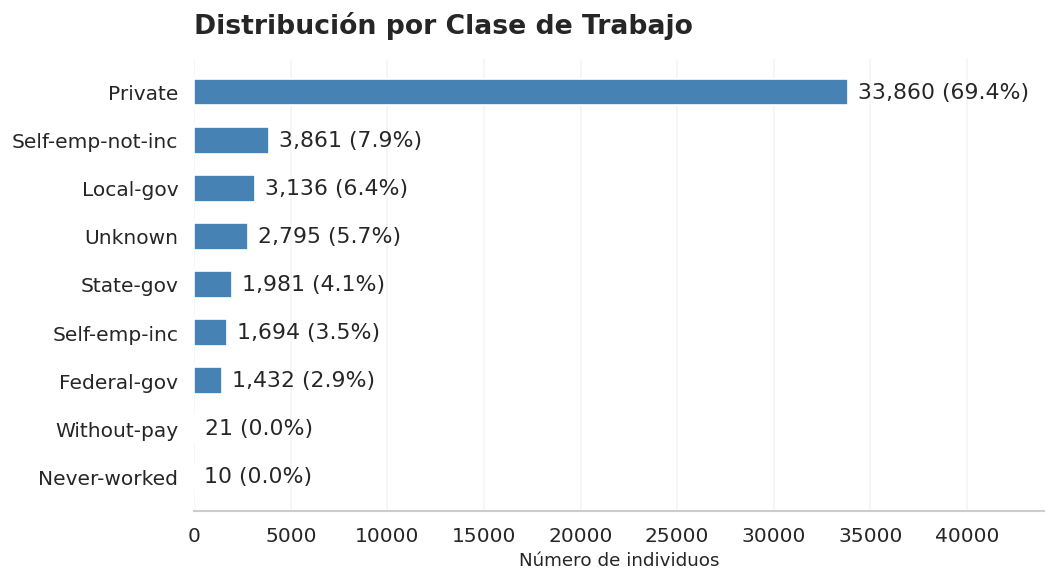

In [229]:
graficar_categorica(
    df05,
    "clase_trabajo",
    "Distribución por Clase de Trabajo"
)

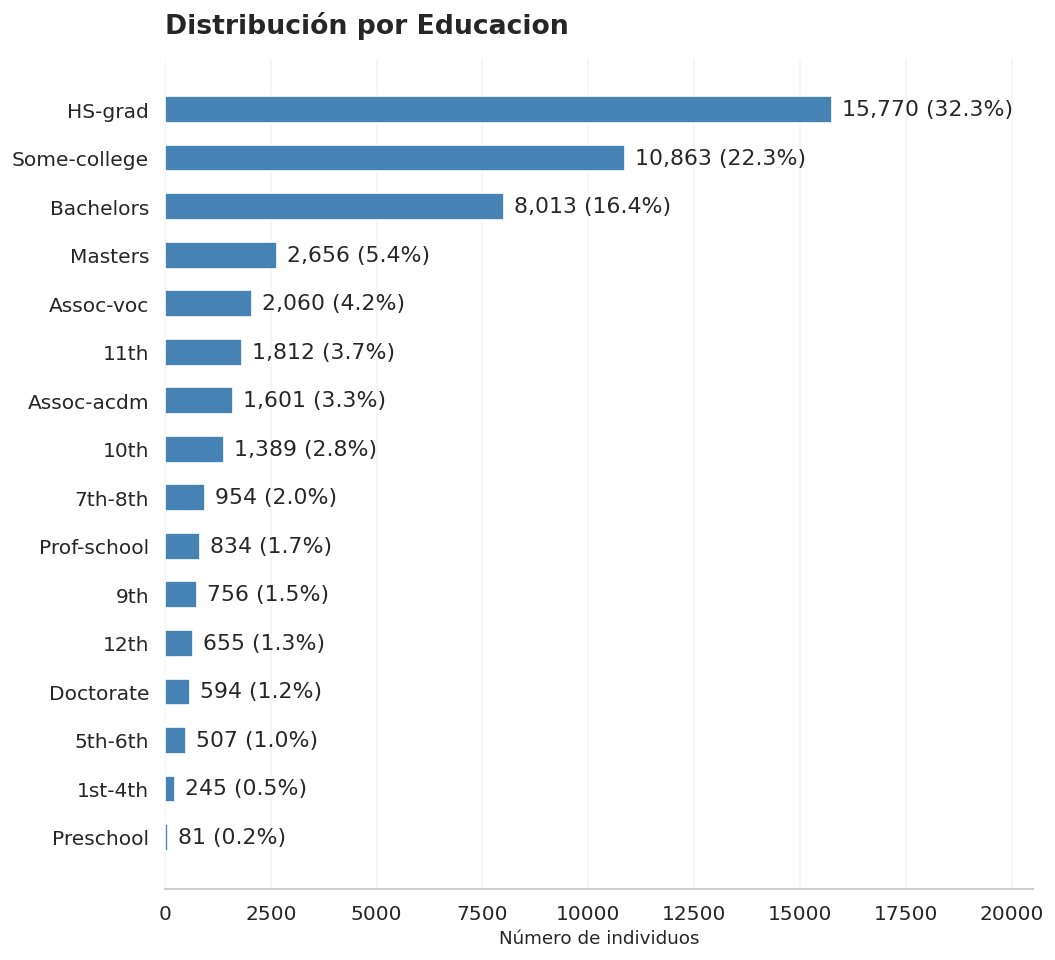

In [230]:
graficar_categorica(
    df05,
    "educacion",
    "Distribución por Educacion"
)

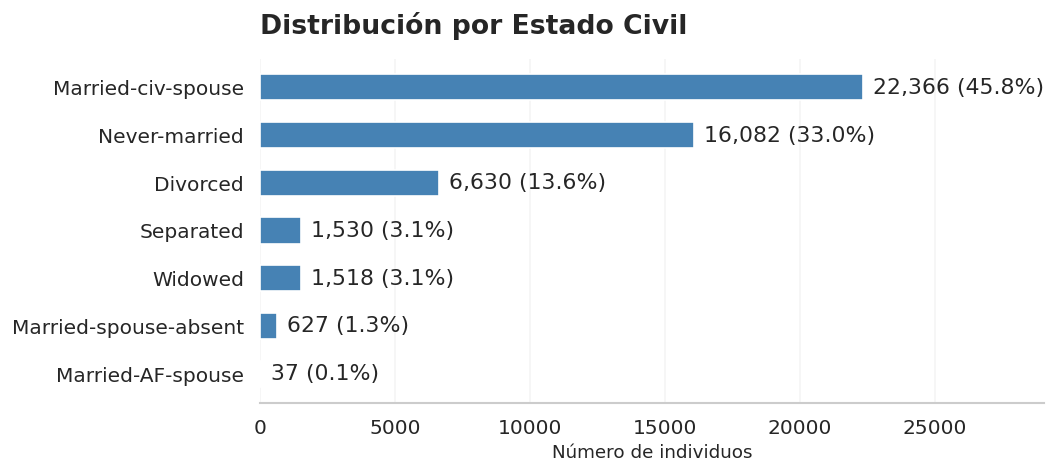

In [231]:
graficar_categorica(
    df05,
    "estado_civil",
    "Distribución por Estado Civil"
)

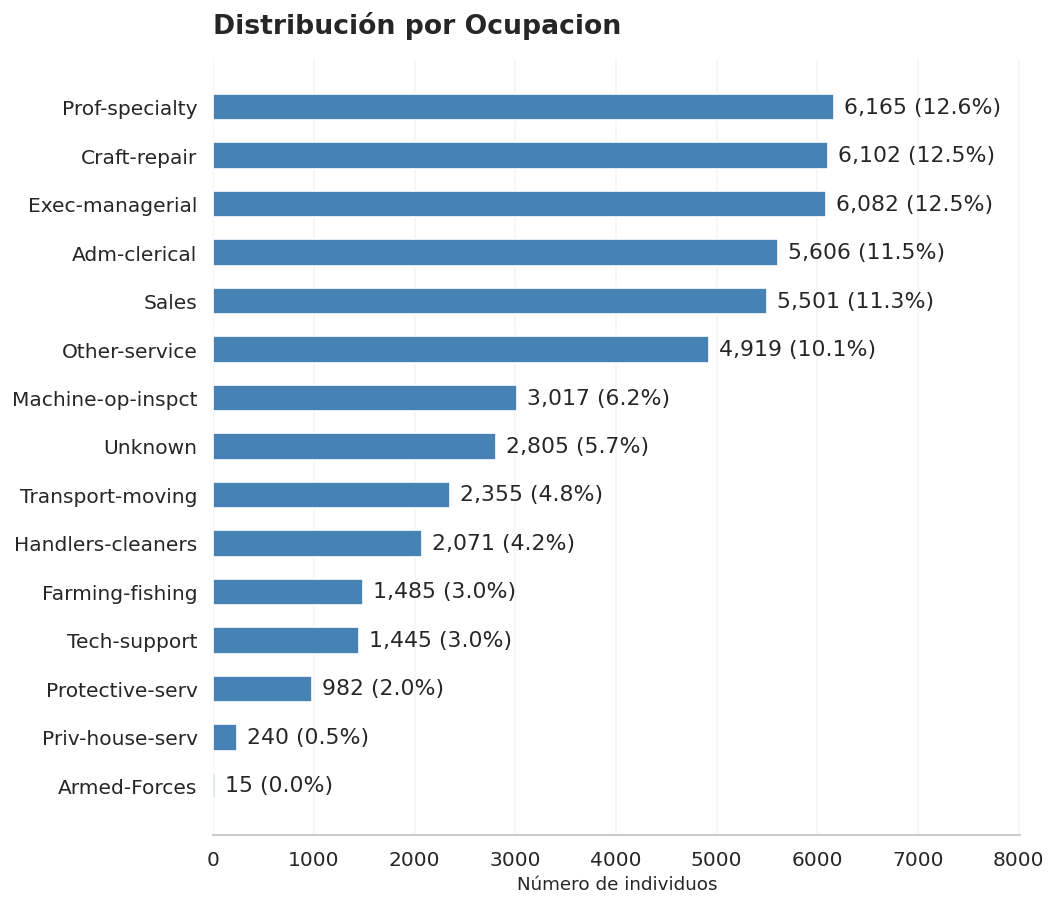

In [232]:
graficar_categorica(
    df05,
    "ocupacion",
    "Distribución por Ocupacion"
)

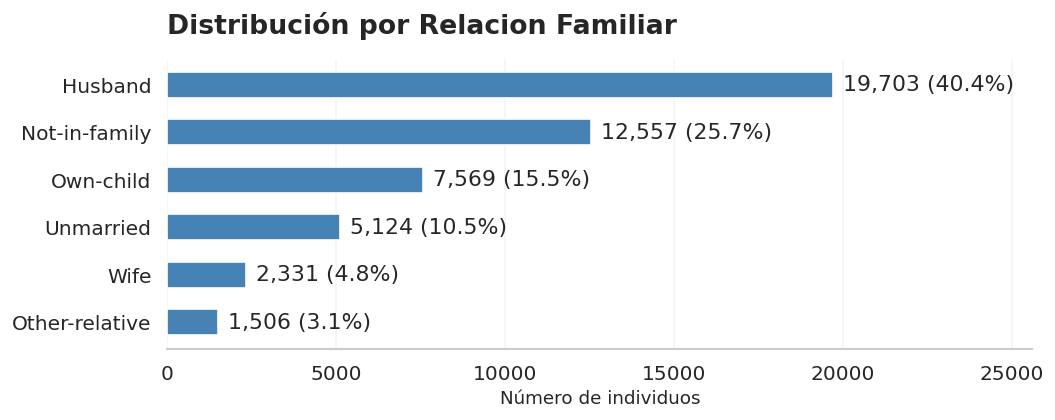

In [233]:
graficar_categorica(
    df05,
    "relacion_familiar",
    "Distribución por Relacion Familiar"
)

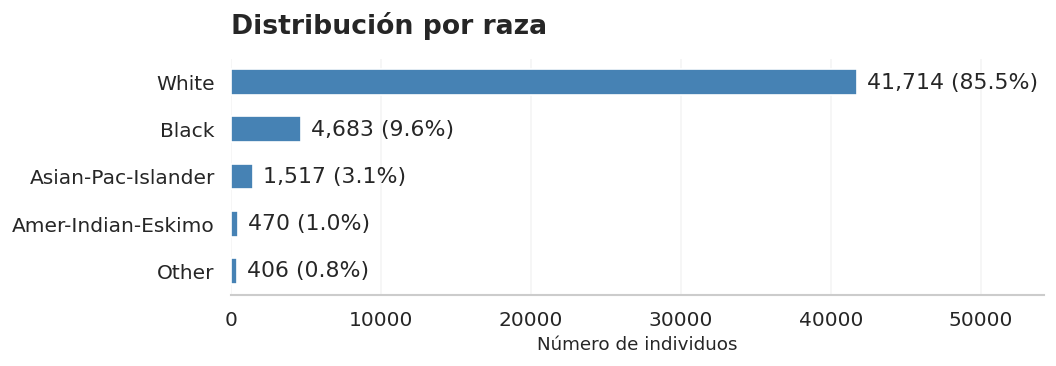

In [234]:
graficar_categorica(
    df05,
    "raza",
    "Distribución por raza"
)

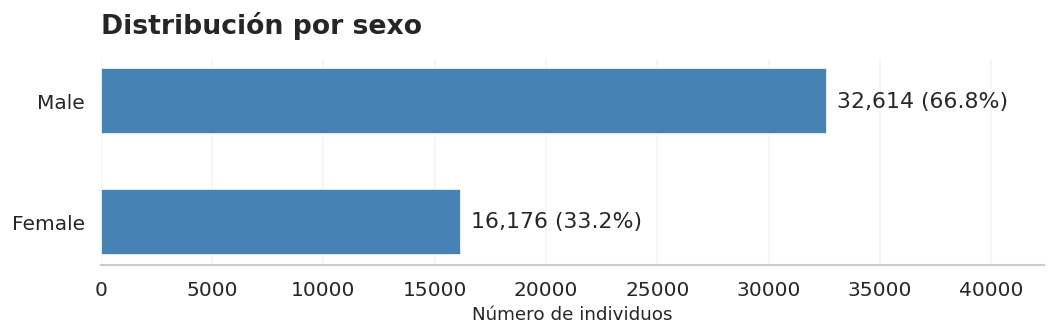

In [235]:
graficar_categorica(
    df05,
    "genero",
    "Distribución por sexo",
)

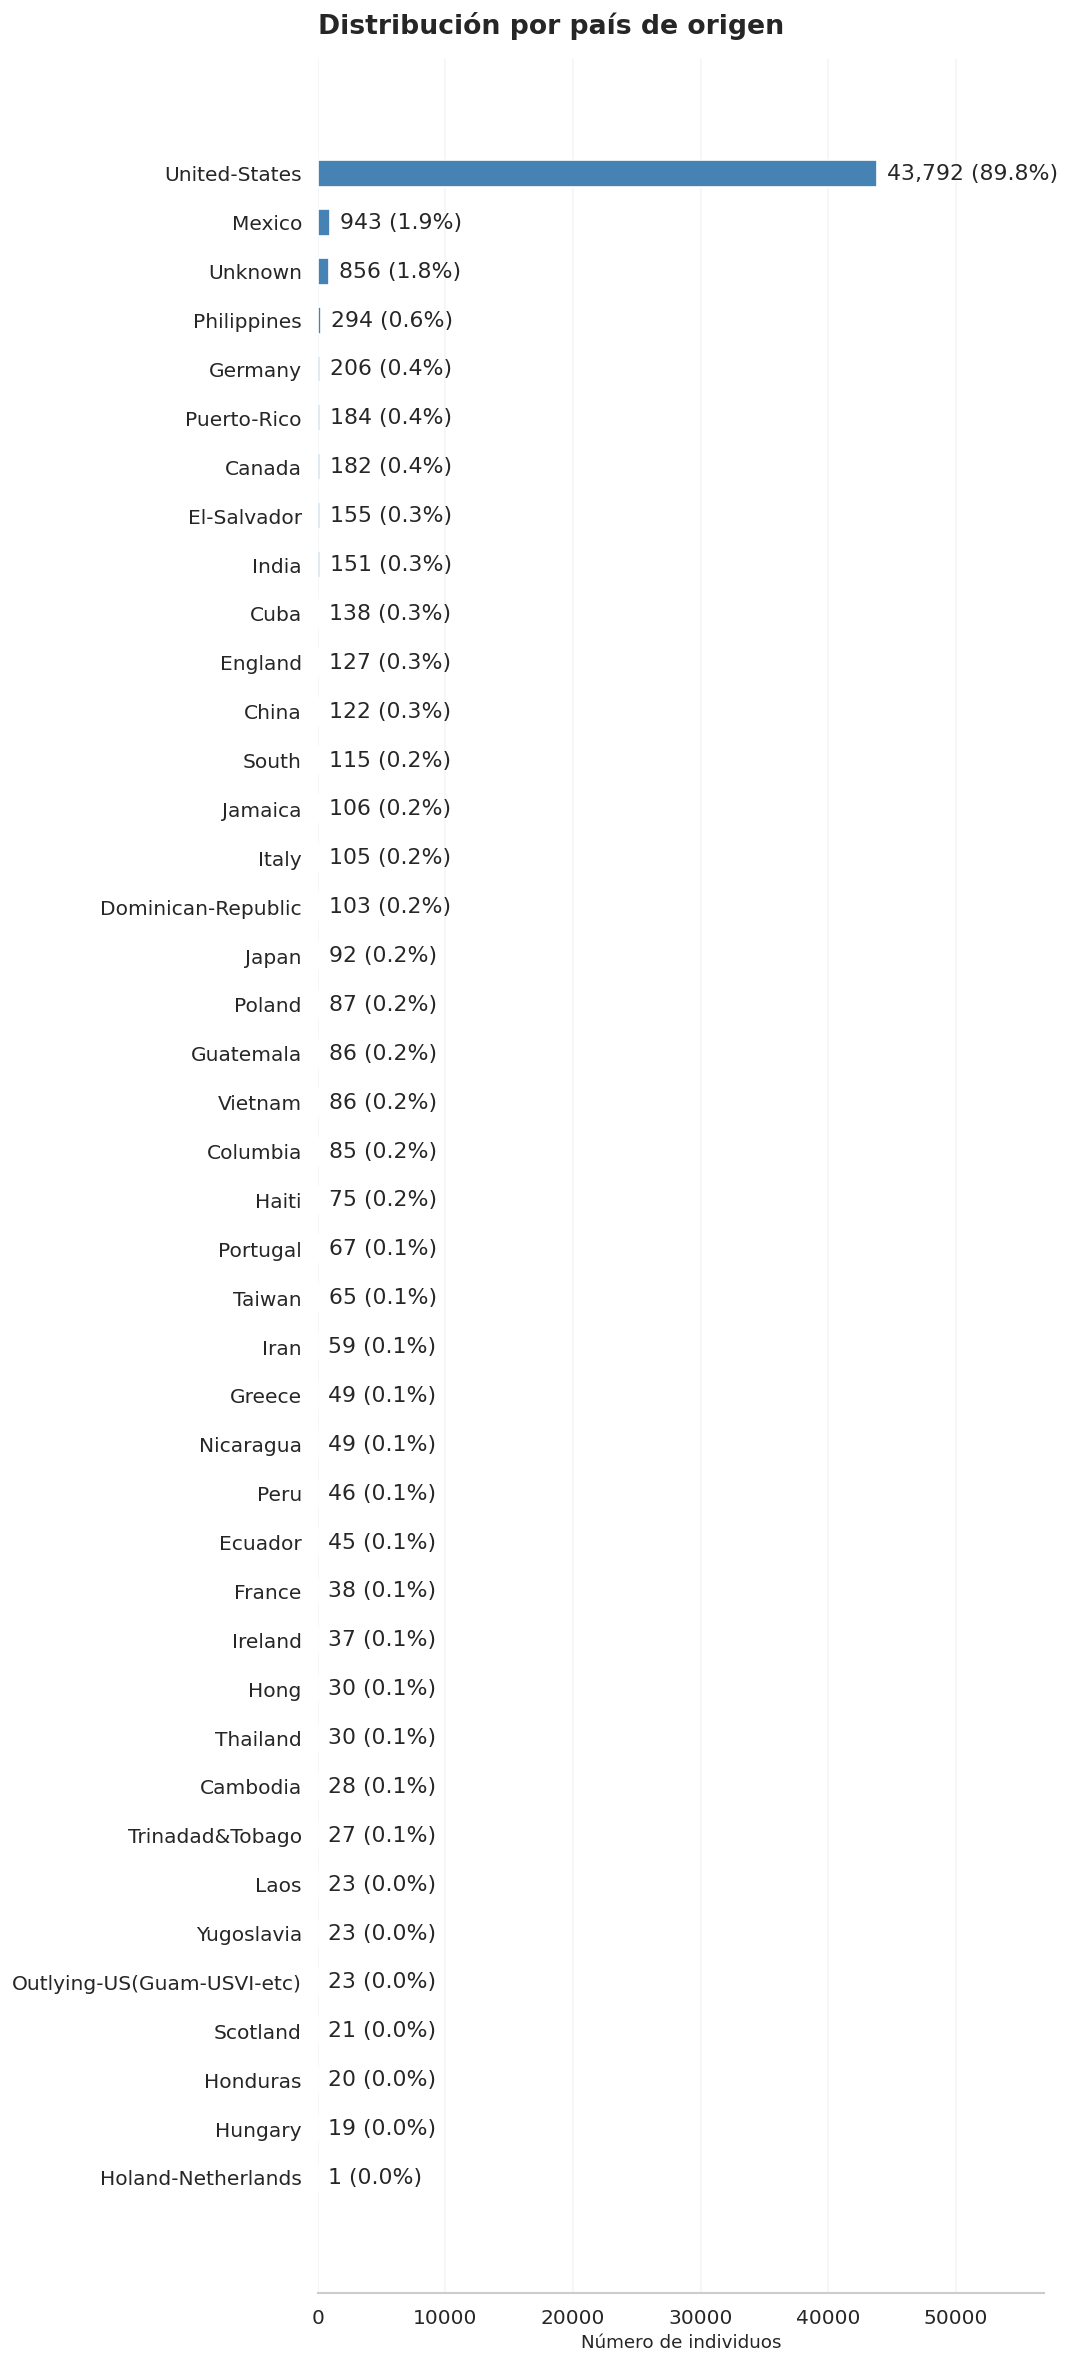

In [236]:
graficar_categorica(
    df05,
    "pais_origen",
    "Distribución por país de origen"
)

##### **Variable Objetivo**

In [237]:
def graficar_objetivo(df, columna, titulo):

    frecuencias = (
        df.groupBy(columna)
        .count()
        .orderBy(F.desc("count"))
        .toPandas()
        .set_index(columna)["count"]
    )

    porcentajes = frecuencias / frecuencias.sum() * 100

    fig, ax = plt.subplots(figsize=(7, 5))

    barras = ax.bar(
        frecuencias.index.astype(str),
        frecuencias.values,
        color=["steelblue", "darkorange"],
        width=0.45
    )

    ax.bar_label(
        barras,
        labels=[
            f"{n:,} ({p:.2f}%)"
            for n, p in zip(frecuencias, porcentajes)
        ],
        padding=8
    )

    ax.set_title(titulo, loc="left", pad=15)
    ax.set_xlabel("Ingresos anuales")
    ax.set_ylabel("Número de individuos")
    ax.set_ylim(0, frecuencias.max() * 1.20)

    ax.grid(axis="x", visible=False)

    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

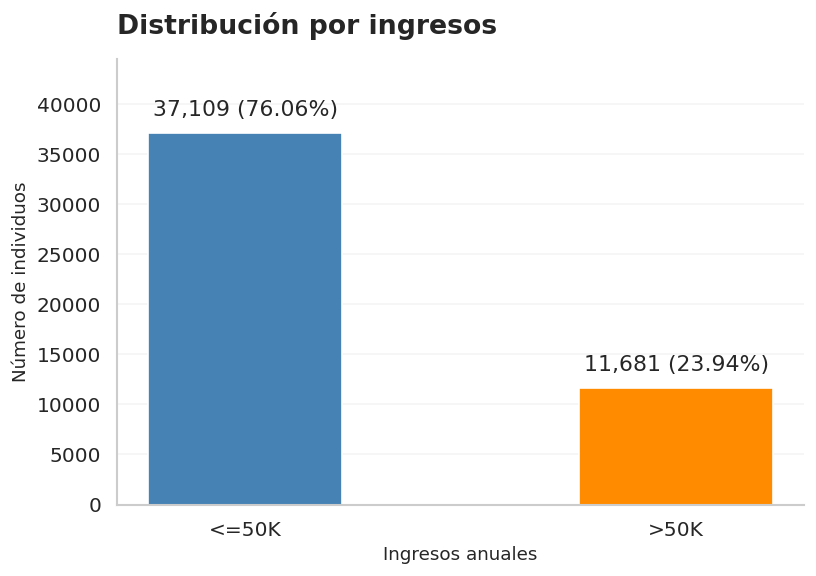

In [238]:
graficar_objetivo(df05, "ingresos", "Distribución por ingresos")


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Univariado Categorico</strong>

<p>
Se identifican distribuciones heterogéneas en las características laborales y educativas de los individuos. Respecto a la clase de trabajo, se evidencia un predominio del sector privado, que concentra el 69,4 % de las observaciones. En cuanto al nivel educativo, las categorías HS-grad, Some-college y Bachelors concentran aproximadamente el 71 % de los registros. 

Respecto a las características demográficas y familiares, se evidencia una concentración de individuos casados (45,8 %) y que nunca se han casado (33 %). Asimismo, se observa una representación desigual en las variables raza, sexo y país de origen, donde la mayoria son hombres blancos originarios de Estados Unidos. Esto puede generar una limitación puesto que los modelos podrían presentar dificultades para generalizar sobre categorías con pocas observaciones.

Finalmente, respecto a la variable objetivo, se evidencia un desbalance de clases, donde el 76,06 % de los individuos presenta ingresos anuales iguales o inferiores a 50.000 dólares, frente al 23,94 % que supera dicho valor. Este comportamiento deberá tenerse en cuenta durante el entrenamiento y la evaluación de los modelos, considerando no solo Accuracy sin complementar con metircas como Precision, Recall, F1-Score, y PR-AUC.
</p>

</div>

#### **Variables Numericas**

In [239]:
# Funcion para graficar variables numericas
def graficar_numerica(
    df,
    columna,
    titulo,
    xlabel,
    bins=30,
    kde=True,
    discrete=False,
    log_scale=False
):

    valores = pd.to_numeric(
        df.select(columna).toPandas()[columna],
        errors="coerce"
    ).dropna()

    media = valores.mean()
    mediana = valores.median()

    fig, ax = plt.subplots(figsize=(11, 5))

    sns.histplot(
        valores,
        bins=bins,
        kde=kde,
        discrete=discrete,
        color=AZUL,
        alpha=0.45,
        edgecolor="white",
        ax=ax
    )

    ax.axvline(
        media,
        color=ROJO,
        linestyle="--",
        linewidth=2,
        label=f"Media: {media:.2f}"
    )

    ax.axvline(
        mediana,
        color=VERDE,
        linestyle=":",
        linewidth=2,
        label=f"Mediana: {mediana:.2f}"
    )

    if log_scale:
        ax.set_yscale("log")

    ax.set_title(titulo, loc="left", pad=15)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Número de individuos")
    ax.legend()

    ax.grid(axis="x", visible=False)

    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

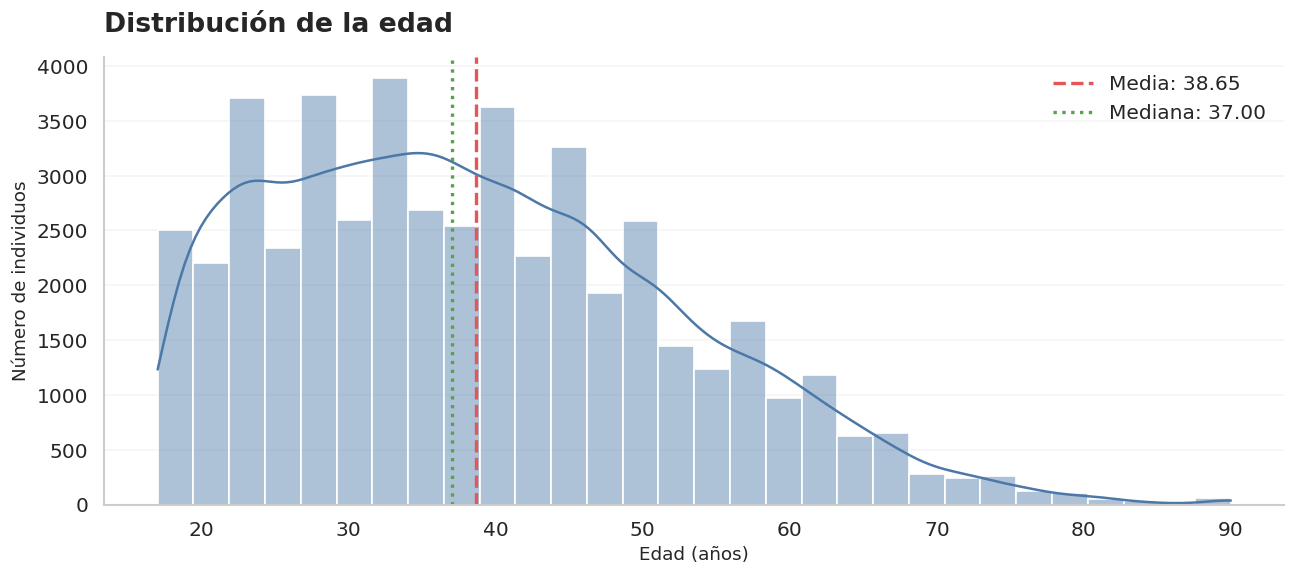

In [240]:
graficar_numerica(
    df05,
    "edad",
    "Distribución de la edad",
    "Edad (años)"
)

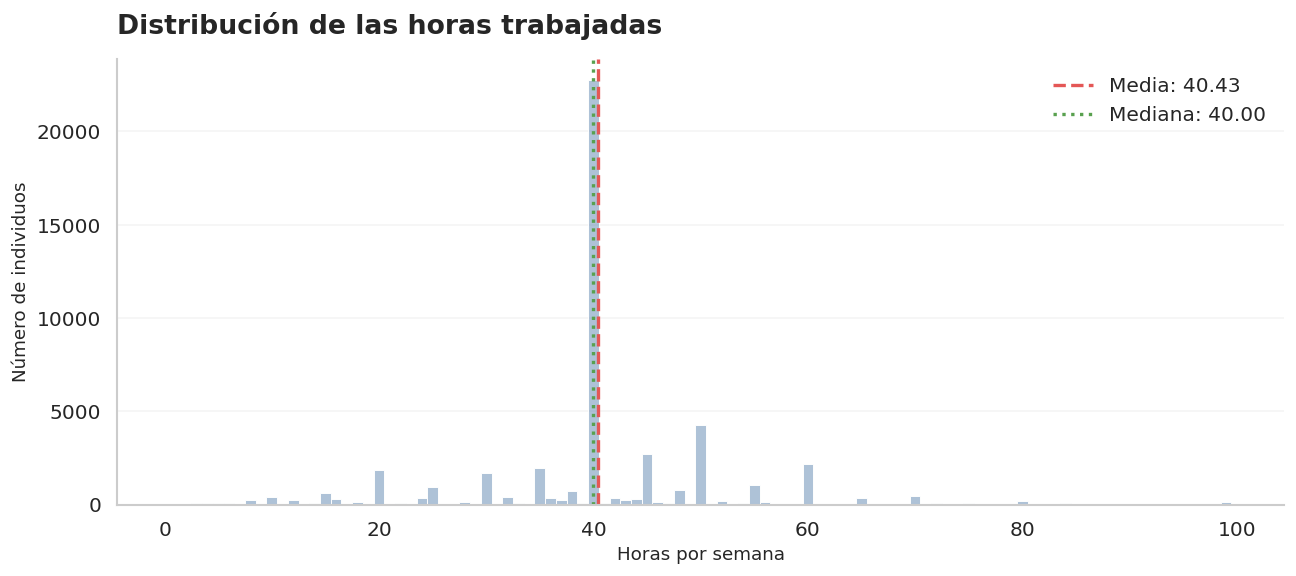

In [241]:
graficar_numerica(
    df05,
    "horas_por_semana",
    "Distribución de las horas trabajadas",
    "Horas por semana",
    kde=False,
    discrete=True
)

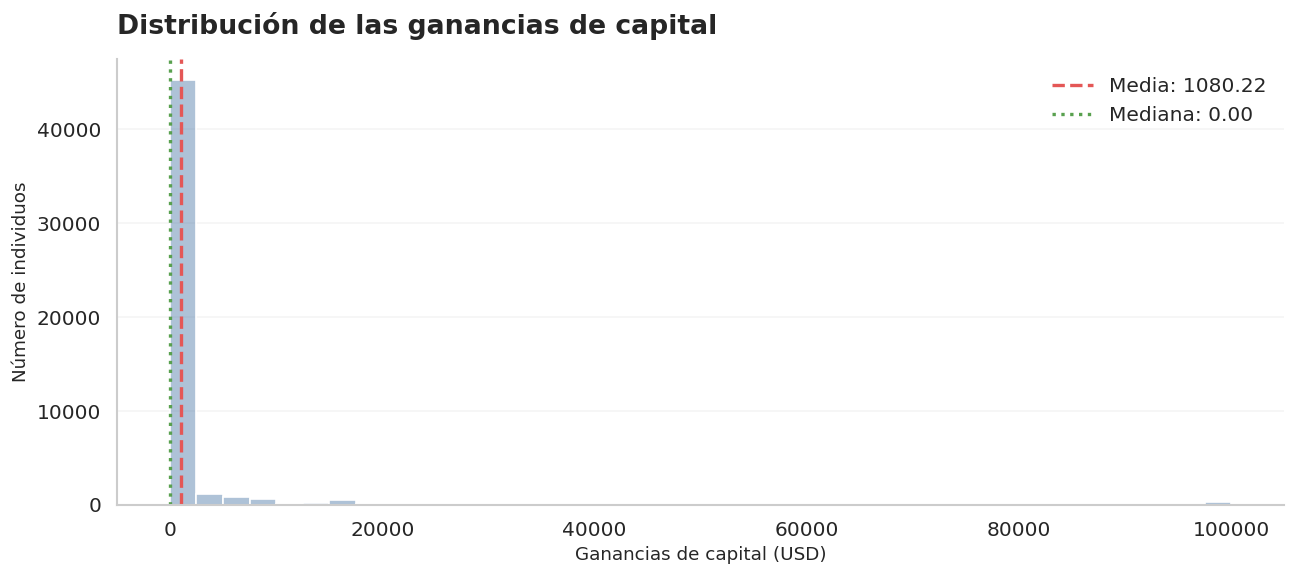

In [242]:
graficar_numerica(
    df05,
    "ganancia_capital",
    "Distribución de las ganancias de capital",
    "Ganancias de capital (USD)",
    bins=40,
    kde=False
)

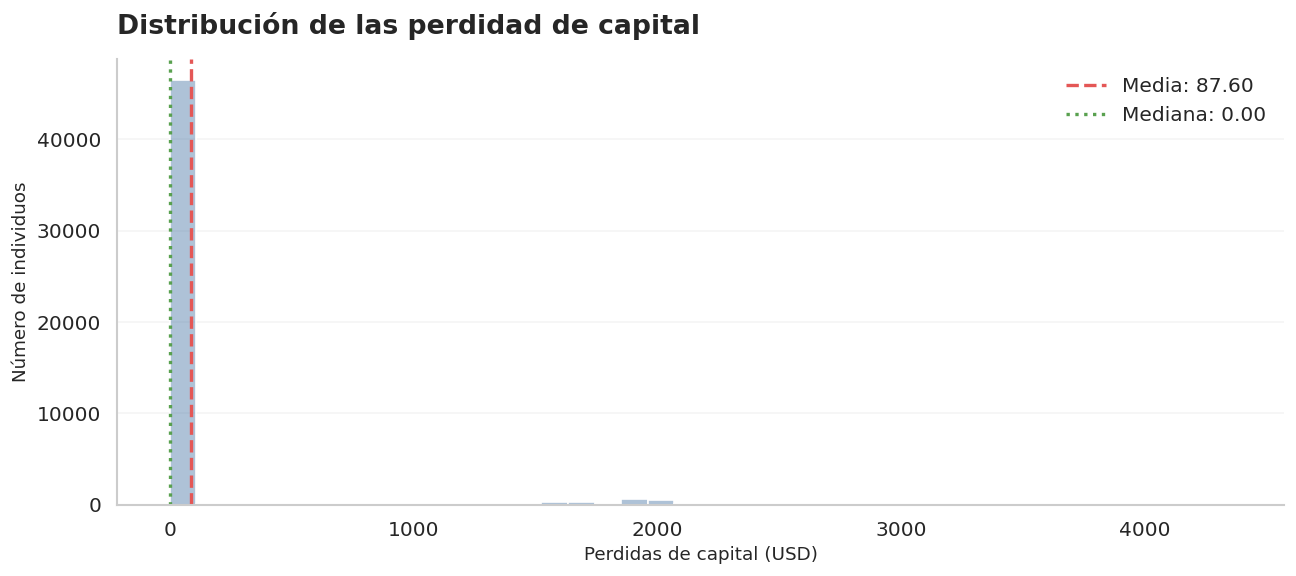

In [243]:
graficar_numerica(
    df05,
    "perdida_capital",
    "Distribución de las perdidad de capital",
    "Perdidas de capital (USD)",
    bins=40,
    kde=False,
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Univariado Numerico</strong>

<p>
La variable edad presenta una distribución con asimetría positiva, con una media de 38,65 años y una mediana de 37 años. Se observa una mayor concentración de individuos entre los 20 y los 50 años. Esto muestra que el conjunto de datos contiene la mayoria de individuos en edad laboral.

Respecto a las horas_por_semana, se evidencia una distribución discreta con una elevada concentración de observaciones alrededor de las 40 horas semanales, coincidiendo con la jornada laboral estandar. También se observan concentraciones secundarias en valores como 20, 30, 45, 50 y 60 horas, reflejando la existencia de diferentes jornadas laborales.

Finalmente, las variables ganancia_capital y perdida_capital tienen concentración de valores en cero, lo cual se evidencia en sus respectivas medianas. Sin embargo, sus medias son de 1.080,22 y 87,60 dólares, respectivamente, debido a la presencia de observaciones de magnitudes considerablemente superiores.
</p>

</div>

### **2.3 - Analisis Bivariado Numerico con Variable Objetivo**

In [244]:
def comparar_numerica(
    df,
    columna,
    titulo,
    xlabel,
    objetivo="ingresos",
    tipo="kde",
    bins=30,
    discrete=False
):

    datos = df.select(columna, objetivo).toPandas()

    datos[columna] = pd.to_numeric(
        datos[columna],
        errors="coerce"
    )

    datos = datos.dropna()

    fig, ax = plt.subplots(figsize=(11, 5))

    if tipo == "kde":

        sns.kdeplot(
            data=datos,
            x=columna,
            hue=objetivo,
            hue_order=ORDEN_INGRESOS,
            palette=PALETA_INGRESOS,
            common_norm=False,
            fill=True,
            alpha=0.20,
            linewidth=2.5,
            cut=0,
            ax=ax
        )

        ax.set_ylabel("Densidad")

    elif tipo == "hist":

        sns.histplot(
            data=datos,
            x=columna,
            hue=objetivo,
            hue_order=ORDEN_INGRESOS,
            palette=PALETA_INGRESOS,
            common_norm=False,
            stat="probability",
            multiple="layer",
            bins=bins,
            discrete=discrete,
            alpha=0.35,
            edgecolor="white",
            ax=ax
        )

        ax.set_ylabel("Frecuencia relativa")

    else:
        raise ValueError("El tipo debe ser 'kde' o 'hist'")

    ax.set_title(titulo, loc="left", pad=15)
    ax.set_xlabel(xlabel)

    sns.move_legend(
        ax,
        "upper right",
        title="Ingresos anuales"
    )

    sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

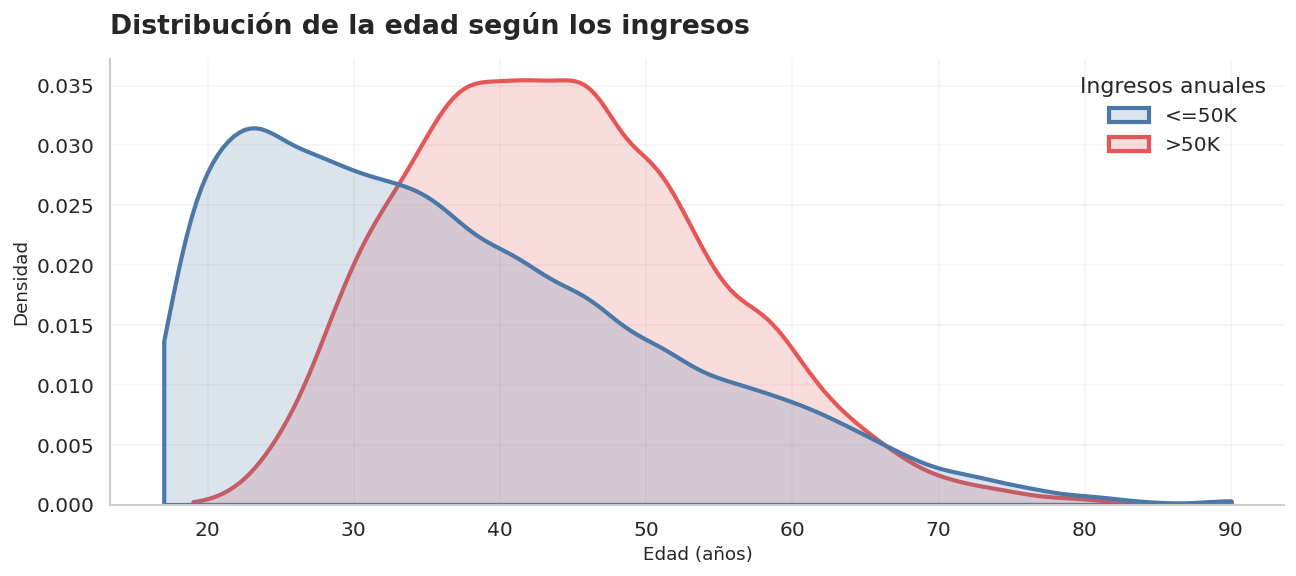

In [245]:
comparar_numerica(
    df05,
    "edad",
    "Distribución de la edad según los ingresos",
    "Edad (años)"
)

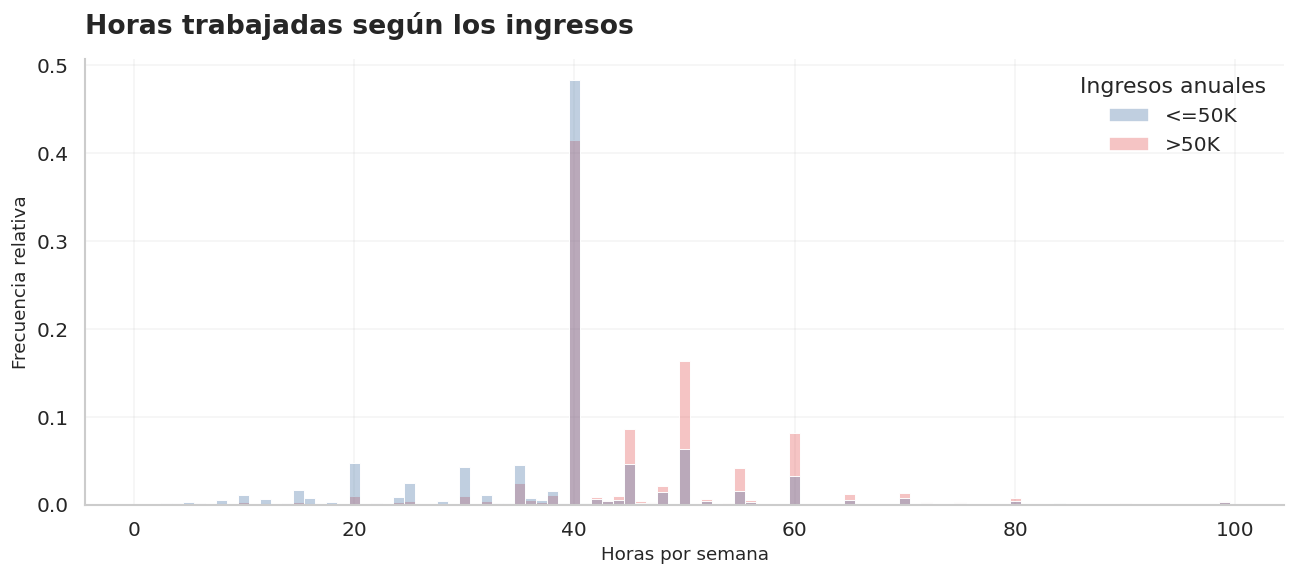

In [246]:
comparar_numerica(
    df05,
    "horas_por_semana",
    "Horas trabajadas según los ingresos",
    "Horas por semana",
    tipo="hist",
    discrete=True
)

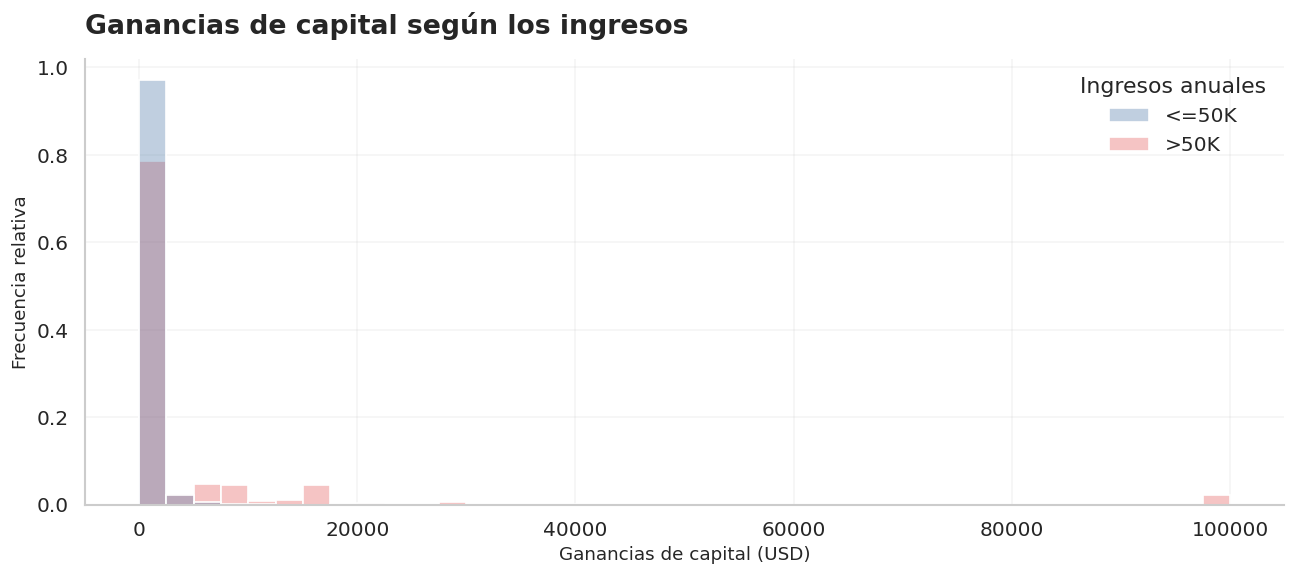

In [247]:
comparar_numerica(
    df05,
    "ganancia_capital",
    "Ganancias de capital según los ingresos",
    "Ganancias de capital (USD)",
    tipo="hist",
    bins=40
)

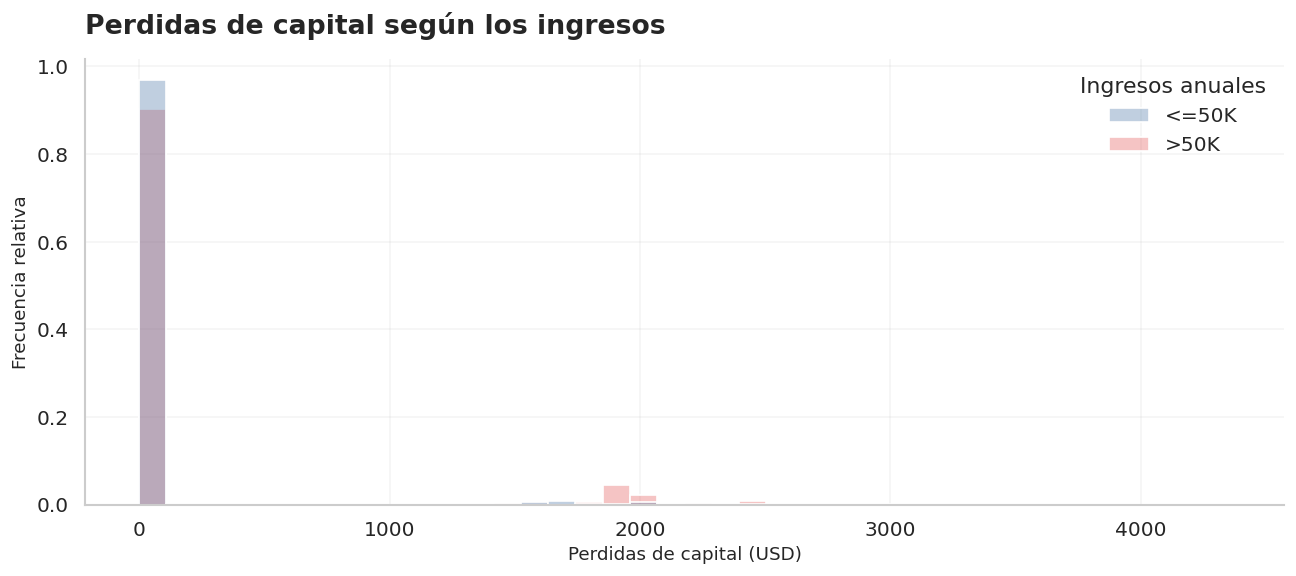

In [248]:
comparar_numerica(
    df05,
    "perdida_capital",
    "Perdidas de capital según los ingresos",
    "Perdidas de capital (USD)",
    tipo="hist",
    bins=40
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Bivariado Numerico</strong>

<p>

Se identifica que los individuos con ingresos iguales o inferiores a 50.000 dólares presentan una mayor concentración relativa entre los 20 y los 35 años, mientras que aquellos con ingresos superiores presentan una mayor concentración entre los 35 y los 55 años. Este comportamiento podría estar relacionado con la experiencia laboral y el desarrollo profesional de los individuos.

Respecto a las horas_por_semana, ambas clases presentan su mayor concentración en las 40 horas semanales. No obstante, los individuos con ingresos superiores a 50.000 dólares presentan una mayor frecuencia relativa en jornadas laborales de 45, 50 y 60 horas. Esto indica que existe una asociación positiva entre la cantidad de horas trabajadas y el nivel de ingresos.

Finalmente, las variables ganancia_capital y perdida_capital, a pesar de presentar una elevada concentración de observaciones alrededor de cero en ambas clases, evidencian diferencias relevantes en sus distribuciones. Los individuos con mayores ingresos presentan una mayor frecuencia relativa de ganancias y pérdidas de capital distintas de cero, en especial en las ganancias de mayor magnitud. 
</p>

</div>

### **2.4 - Analisis Bivariado Categorico**

In [249]:
def comparar_categorica(
    df,
    columna,
    titulo,
    etiquetas=None,
    top_n=None
):

    # Calcular el total de individuos y de ingresos >50K
    resumen = (
        df.groupBy(columna)
        .agg(
            F.count("*").alias("TotalIndividuos"),
            F.sum(
                F.when(F.col("ingresos") == ">50K", 1)
                .otherwise(0)
            ).alias("TotalIngresosAltos")
        )
        .toPandas()
    )

    # Porcentaje general de ingresos >50K
    porcentaje_general = (
        resumen["TotalIngresosAltos"].sum() /
        resumen["TotalIndividuos"].sum() * 100
    )

    # Porcentaje de ingresos >50K por categoría
    resumen["Porcentaje"] = (
        resumen["TotalIngresosAltos"] /
        resumen["TotalIndividuos"] * 100
    )

    # Seleccionar las categorías más frecuentes
    if top_n is not None:
        resumen = resumen.nlargest(top_n, "TotalIndividuos")

    # Renombrar categorías
    if etiquetas:
        resumen[columna] = resumen[columna].replace(etiquetas)

    # Ordenar por porcentaje de ingresos altos
    resumen = resumen.sort_values(
        "Porcentaje",
        ascending=False
    )

    # Ajustar dinámicamente la altura
    altura = max(3, len(resumen) * 0.50 + 1.5)

    fig, ax = plt.subplots(figsize=(11, altura))

    barras = ax.barh(
        resumen[columna].astype(str),
        resumen["Porcentaje"],
        color=AZUL,
        height=0.55
    )

    ax.bar_label(
        barras,
        labels=[
            f"{p:.1f}% (n={n:,})"
            for p, n in zip(
                resumen["Porcentaje"],
                resumen["TotalIndividuos"]
            )
        ],
        padding=6,
        fontsize=9
    )

    # Línea de referencia global
    ax.axvline(
        porcentaje_general,
        color=ROJO,
        linestyle="--",
        linewidth=2,
        label=f"Porcentaje general: {porcentaje_general:.2f}%"
    )

    ax.invert_yaxis()
    ax.set_title(titulo, loc="left", pad=15)
    ax.set_xlabel("Individuos con ingresos superiores a 50K (%)")
    ax.set_ylabel("")

    ax.xaxis.set_major_formatter(mtick.PercentFormatter(100))

    ax.set_xlim(0, 100)

    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax, left=True)

    plt.tight_layout()
    plt.show()

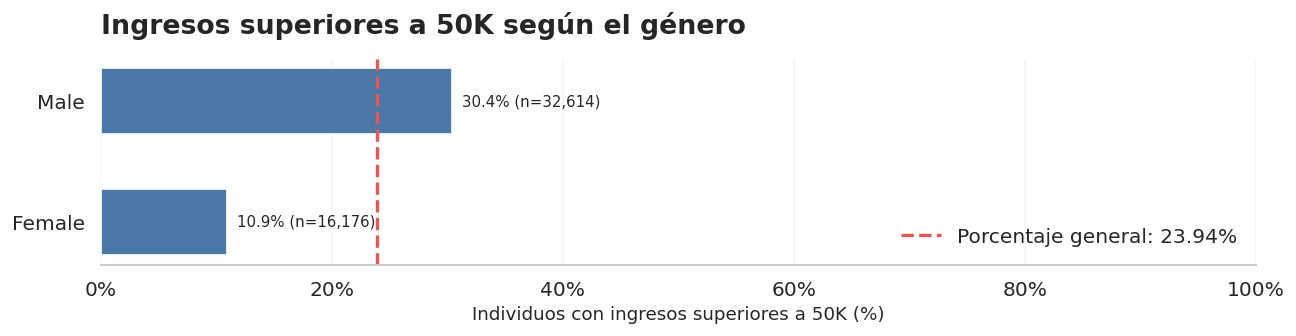

In [250]:
comparar_categorica(
    df05,
    "genero",
    "Ingresos superiores a 50K según el género"
)

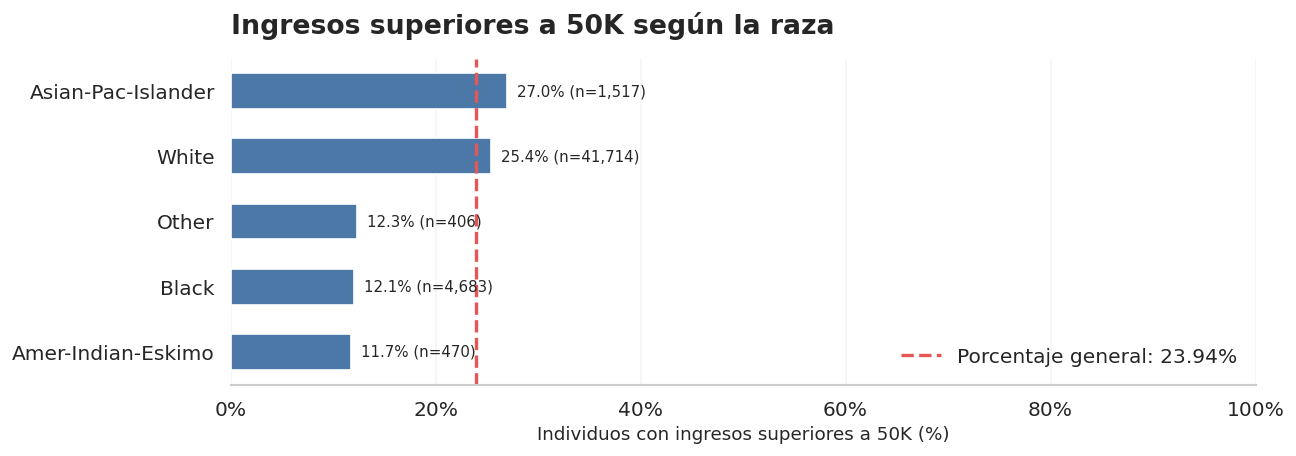

In [251]:
comparar_categorica(
    df05,
    "raza",
    "Ingresos superiores a 50K según la raza"
)

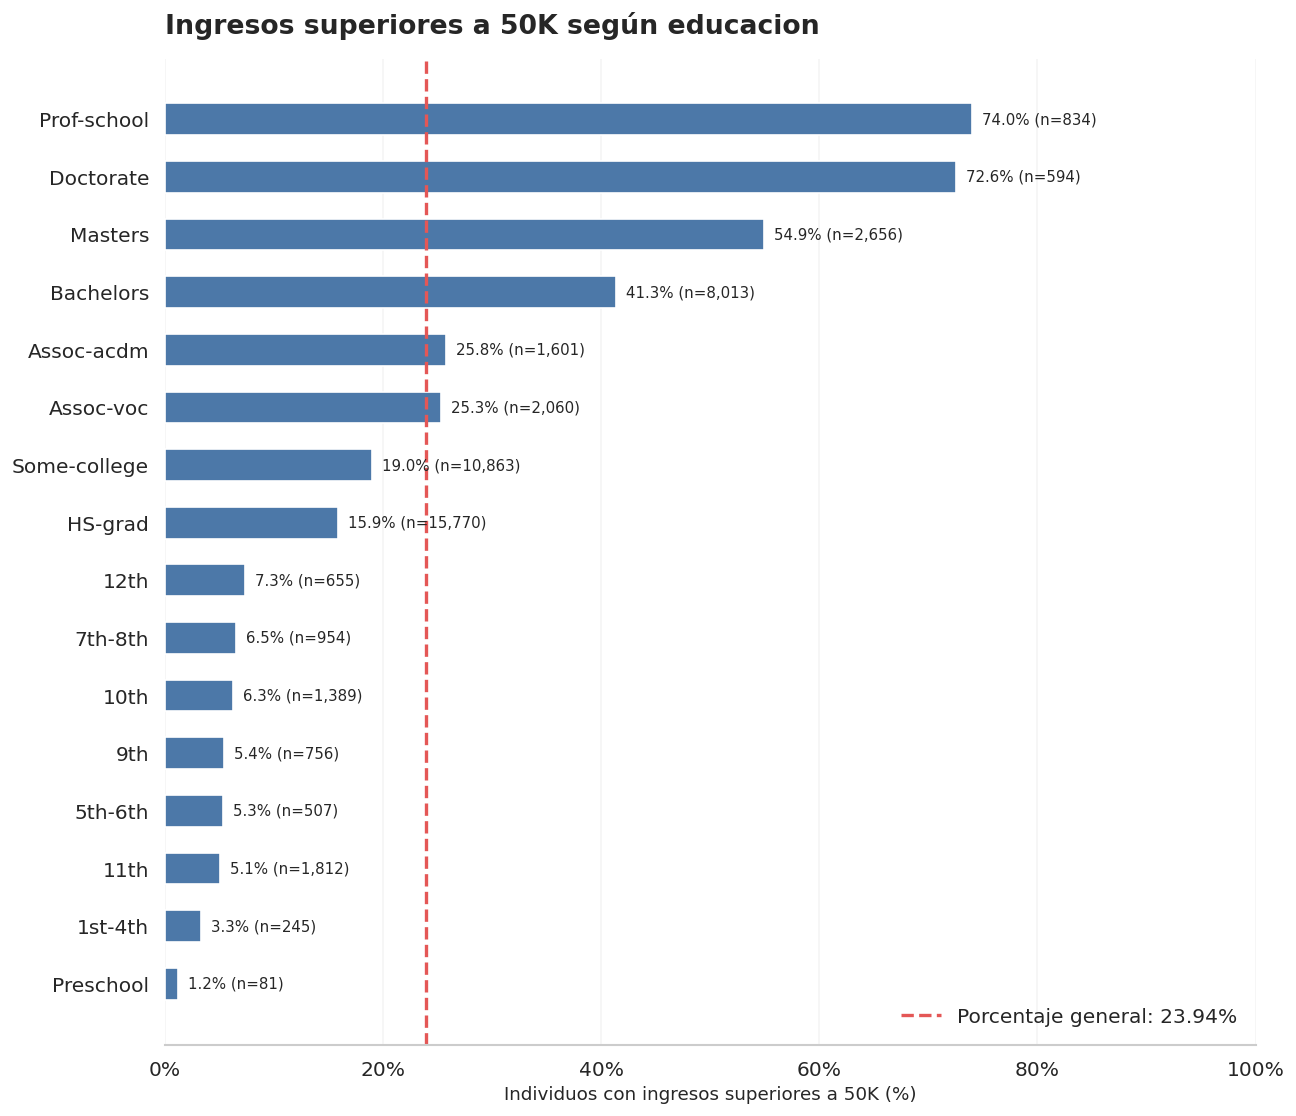

In [252]:
comparar_categorica(
    df05,
    "educacion",
    "Ingresos superiores a 50K según educacion"
)

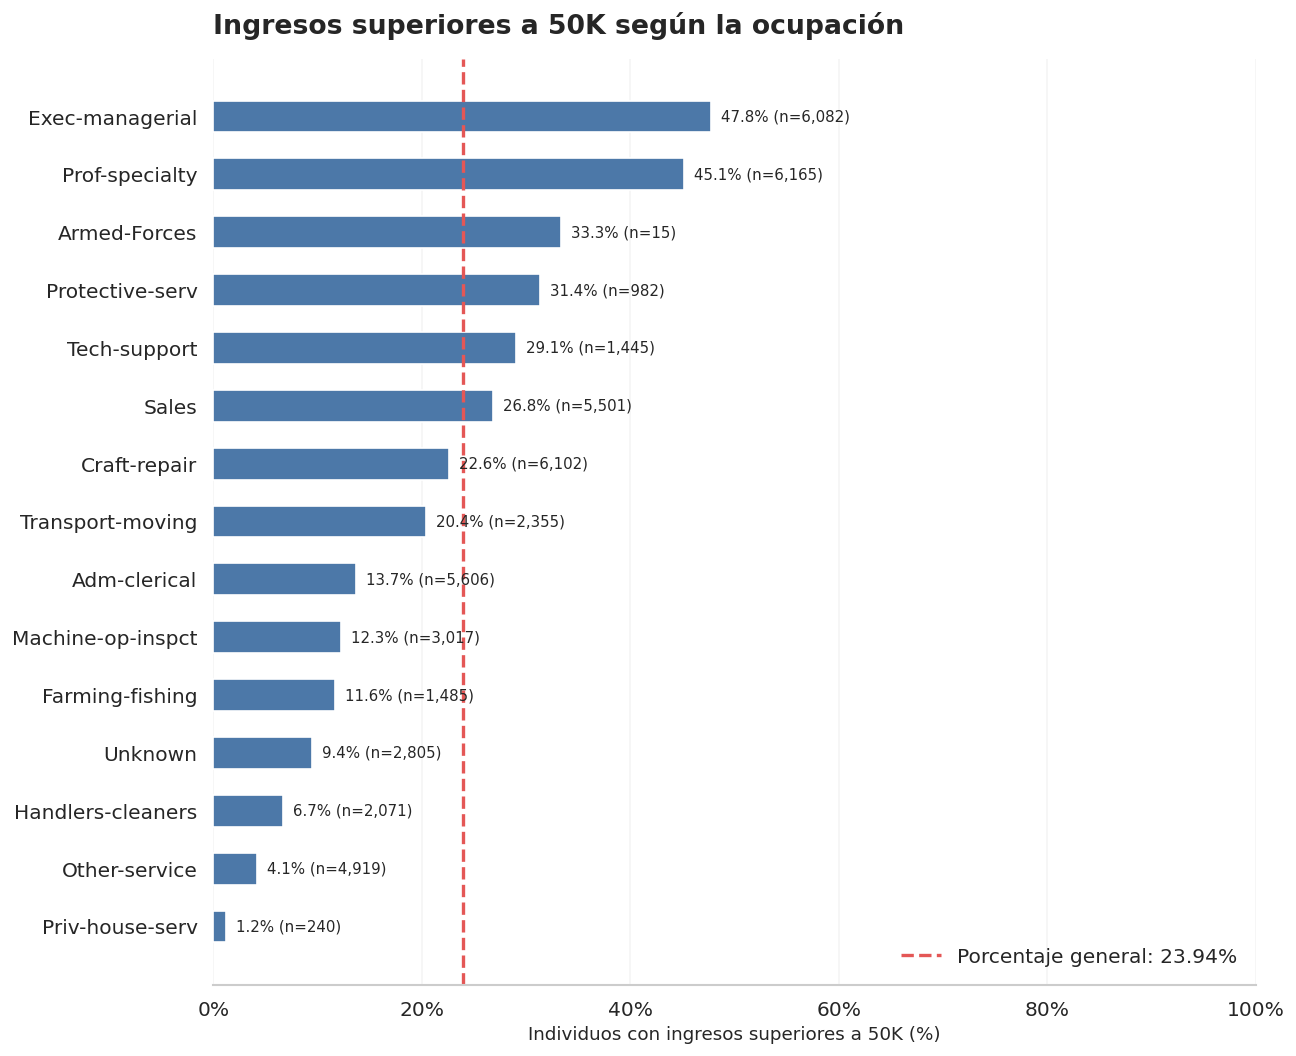

In [253]:
comparar_categorica(
    df05,
    "ocupacion",
    "Ingresos superiores a 50K según la ocupación"
)

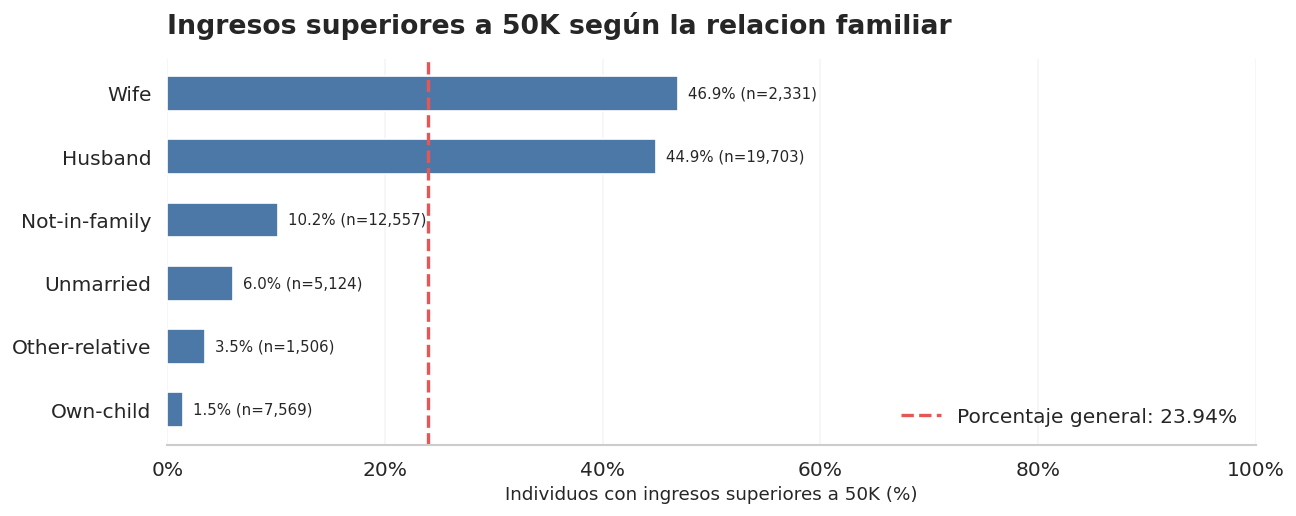

In [254]:
comparar_categorica(
    df05,
    "relacion_familiar",
    "Ingresos superiores a 50K según la relacion familiar"
)

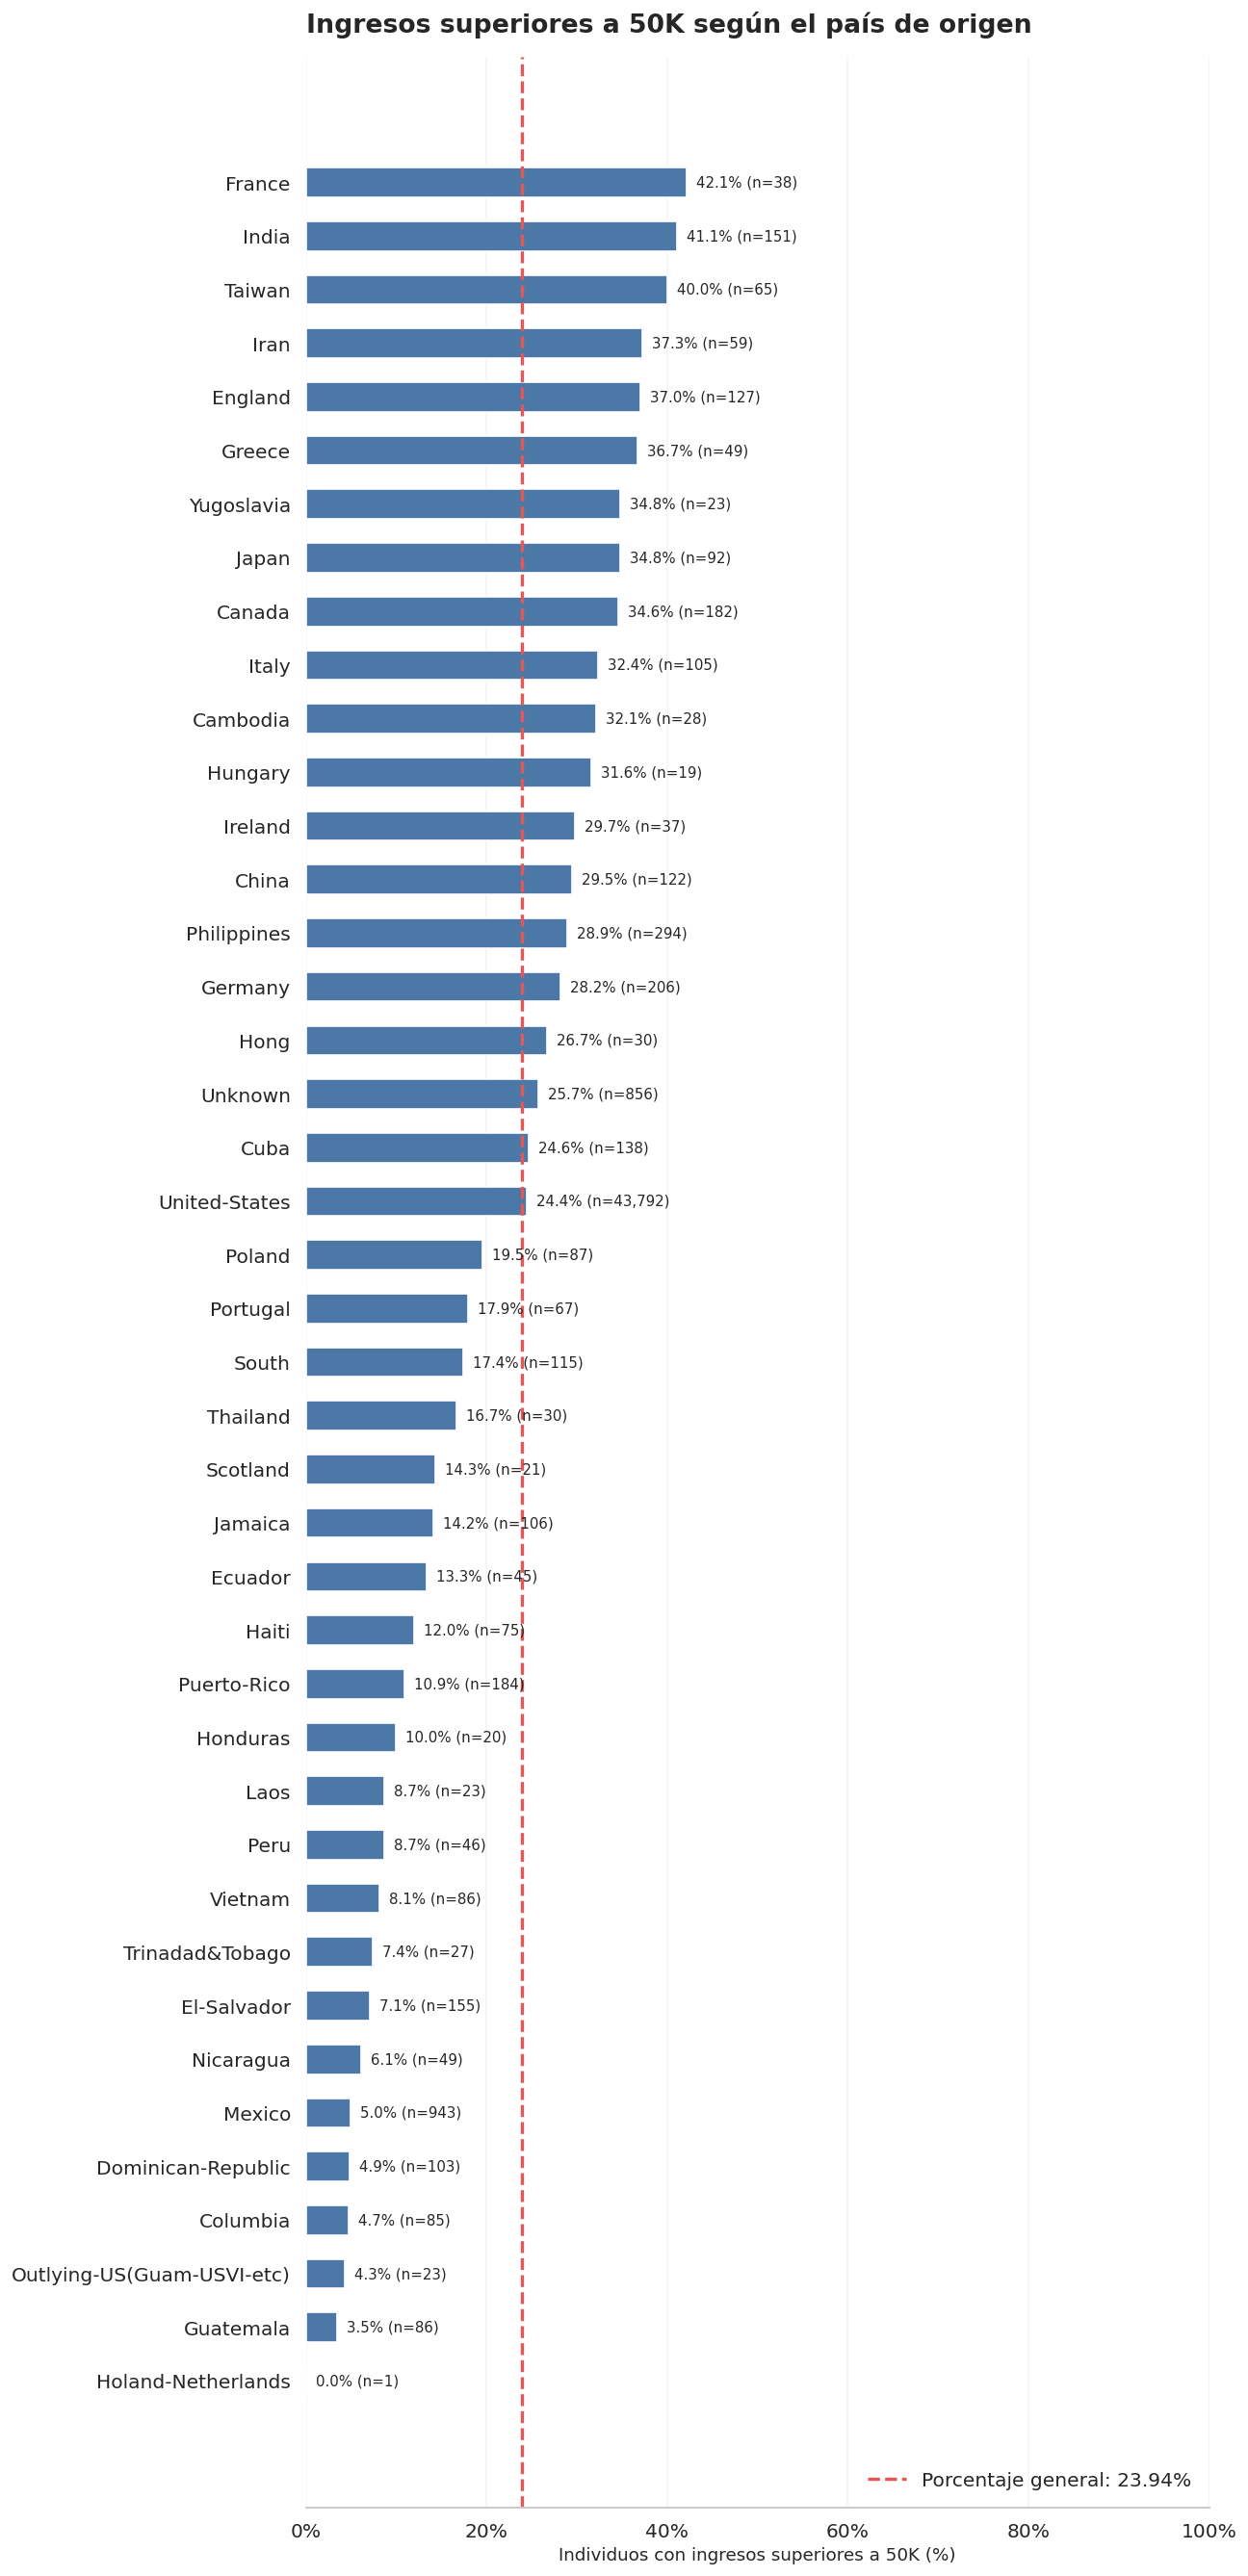

In [255]:
comparar_categorica(
    df05,
    "pais_origen",
    "Ingresos superiores a 50K según el país de origen",
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Bivariado Categorico</strong>

<p>
Para el analisis de las variables categoricas con la objetivo se toma como referencia el porcentaje general del 23,94 % de individuos con ingresos superiores a 50.000 dólares. En particular, el nivel educativo y la ocupación presentan asociaciones relevantes con los ingresos. Los individuos con estudios profesionales, doctorados y maestrías presentan porcentajes del 74 %, 72,6 % y 54,9 %, respectivamente, mientras que aquellos con educación secundaria completa (HS-grad) presentan un porcentaje del 15,9 %. De manera similar, las ocupaciones ejecutivas y gerenciales (47,8 %) y las profesiones especializadas (45,1 %) superan considerablemente el porcentaje general. Esto sugiere que las variables educativas y laborales aportaran de manera considerable a la clasificacion.

Respecto a las características demográficas y familiares, se evidencia una diferencia de 19,5 puntos porcentuales entre hombres (30,4 %) y mujeres (10,9 %). Asimismo, se observan diferencias entre las categorías de raza, donde Asian-Pac-Islander y White presentan porcentajes superiores al general.  No obstante se deben considerar posibles sesgos demográficos durante la evaluación de los modelos.

Finalmente, el país de origen presenta una elevada variabilidad entre sus categorías, destacándose Francia (42,1 %), India (41,1 %) y Taiwán (40 %) frente a países como México (5 %) y Colombia (4,7 %). No obstante, esta alta variabilidad se explica por las diferencias considerables en el número de observaciones por categoría. 

</p>

</div>

## **3 - Preparacion y Transformacion para Modelos**

In [159]:
## Identificacion de Variables Numericas y Categoricas

variableObjetivo = "ingresos"

varNumericas = [
    campo.name
    for campo in df05.schema.fields
    if isinstance(campo.dataType, NumericType)
    and campo.name != variableObjetivo
]

varCategoricas = [
    campo.name
    for campo in df05.schema.fields
    if isinstance(campo.dataType, StringType)
    and campo.name != variableObjetivo
]

### **Codificacion Variable Objetivo**

In [160]:
### Se codifica variable binaria objetiva como 0 y 1
df06 = df05.withColumn(
    "label",
    F.when(F.col("ingresos") == "<=50K", 0.0)
     .when(F.col("ingresos") == ">50K", 1.0)
)

df06 = df06.drop("ingresos")

df06.columns

['edad',
 'clase_trabajo',
 'educacion',
 'estado_civil',
 'ocupacion',
 'relacion_familiar',
 'raza',
 'genero',
 'ganancia_capital',
 'perdida_capital',
 'horas_por_semana',
 'pais_origen',
 'label']

### **Division Datos (Prueba = 20%)**

In [161]:
## Se generan Dataframes de entrenamiento y prueba

train, test = df06.randomSplit(
    [0.8, 0.2],
    seed=42
)

train = train.cache()
test = test.cache()

totalTrain = train.count()
totalTest = test.count()

print(f"Registros de entrenamiento: {totalTrain:,}")
print(f"Registros de prueba: {totalTest:,}")

Registros de entrenamiento: 38,975
Registros de prueba: 9,815


In [162]:
def mostrar_distribucion(df, nombre):

    total = df.count()

    print(f"\nConjunto de {nombre}")
    print(f"Total de registros: {total:,}")

    (
        df.groupBy("label")
        .count()
        .withColumn(
            "Porcentaje",
            F.round(F.col("count") / total * 100, 2)
        )
        .orderBy("label")
        .show()
    )

In [163]:
mostrar_distribucion(train, "entrenamiento")
mostrar_distribucion(test, "prueba")


Conjunto de entrenamiento
Total de registros: 38,975
+-----+-----+----------+
|label|count|Porcentaje|
+-----+-----+----------+
|  0.0|29660|      76.1|
|  1.0| 9315|      23.9|
+-----+-----+----------+


Conjunto de prueba
Total de registros: 9,815
+-----+-----+----------+
|label|count|Porcentaje|
+-----+-----+----------+
|  0.0| 7449|     75.89|
|  1.0| 2366|     24.11|
+-----+-----+----------+



### **Pipeline Transformacion Variables Categoricas**

In [164]:
### Indexacion de variables categoricas: Convertir categoria en indice numerico
indices = [
    StringIndexer(
        inputCol=variable,
        outputCol=variable + "_IND",
        handleInvalid="keep"
    )
    for variable in varCategoricas
]


### Encoder: Remover orden artificial creado por  indexacion (Modelos Sensibles: Regresion Logistica, MLP)
columnasIndexadas = [
    variable + "_IND"
    for variable in varCategoricas
]

columnasCodificadas = [
    variable + "_OHE"
    for variable in varCategoricas
]

encoder = OneHotEncoder(
    inputCols=columnasIndexadas,
    outputCols=columnasCodificadas,
    handleInvalid="keep",
    dropLast=False
)


### Vector Caracteristicas: Se utilizan variables numericas y categoricas codificadas
columnasPredictoras = (
    varNumericas + columnasCodificadas
)

varIndependientes = VectorAssembler(
    inputCols=columnasPredictoras,
    outputCol="features"
)


### Escalamiento de variables: Se estandarizan para modelos sensibles a magnitud de variables
### Nota: Se mantiene vector escalado y normal para uso dependiendo del modelo
scaler = StandardScaler(
    inputCol="features",
    outputCol="features_scaled",
    withStd=True,
    withMean=False
)

In [165]:
### Creacion e instanciacion de tuberia
tuberia = Pipeline(
    stages=(
        indices +
        [
            encoder,
            varIndependientes,
            scaler
        ]
    )
)

modeloTuberia = tuberia.fit(train)

In [166]:
### Transformacion Conjunto de Entrenamiento y Prueba

trainModelos = (
    modeloTuberia.transform(train)
    .select(
        "features",
        "features_scaled",
        "label"
    )
    .cache()
)

testModelos = (
    modeloTuberia.transform(test)
    .select(
        "features",
        "features_scaled",
        "label"
    )
    .cache()
)

trainModelos.show(5, truncate=False)

print(f"Train original: {totalTrain:,}")
print(f"Train preparado: {trainModelos.count():,}")

print(f"Test original: {totalTest:,}")
print(f"Test preparado: {testModelos.count():,}")

+------------------------------------------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|features                                                                      |features_scaled                                                                                                                                                                                                                |label|
+------------------------------------------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|(122,[0,3,4,22,38,47,64,67,74,78],[17.0,40.0,1.0,1.0,1.0,1.0,1.0,1

## **4 - Implementacion de Modelos de Machine Learning usando MLlib**


### **Funciones Auxiliares para Evaluacion de modelos**

In [174]:
### Evaluacion de Modelos con las siguientes metricas 
### AUC-ROC	Capacidad de diferenciación entre ambas clases a través de distintos umbrales.
### PR-AUC	Rendimiento sobre la clase positiva ante el desbalance de clases.
### Accuracy	Proporción total de predicciones correctas.
### Precision	Proporción de derrames predichos que realmente corresponden a derrames.
### Recall	Proporción de derrames reales identificados correctamente.
### F1-Score Media armónica entre Precision y Recall.
def evaluar_modelo(predicciones, nombre):

    evaluadorROC = BinaryClassificationEvaluator(
        labelCol="label",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    )

    evaluadorPR = BinaryClassificationEvaluator(
        labelCol="label",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderPR"
    )

    evaluadorMulti = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricLabel=1.0
    )

    resultados = {
        "Modelo": nombre,

        "AUC-ROC": evaluadorROC.evaluate(predicciones),

        "PR-AUC": evaluadorPR.evaluate(predicciones),

        "Accuracy": evaluadorMulti.evaluate(
            predicciones,
            {evaluadorMulti.metricName: "accuracy"}
        ),

        "Precision": evaluadorMulti.evaluate(
            predicciones,
            {evaluadorMulti.metricName: "weightedPrecision"}
        ),

        "Recall": evaluadorMulti.evaluate(
            predicciones,
            {evaluadorMulti.metricName: "weightedRecall"}
        ),

        "F1-Score": evaluadorMulti.evaluate(
            predicciones,
            {evaluadorMulti.metricName: "weightedFMeasure"}
        )
    }



    print(f"Resultados: {nombre}")
    print("-" * 40)

    for metrica, valor in resultados.items():
        if metrica != "Modelo":
            print(f"{metrica}: {valor:.4f}")

    return resultados

In [175]:
### Matriz de Confusion
def graficar_matriz_confusion(predicciones, nombre):

    conteos = (
        predicciones
        .groupBy("label", "prediction")
        .count()
        .collect()
    )

    matriz = np.zeros((2, 2), dtype=int)

    for fila in conteos:
        matriz[
            int(fila["label"]),
            int(fila["prediction"])
        ] = fila["count"]

    porcentajes = matriz / matriz.sum() * 100

    etiquetas = np.array([
        [
            f"{matriz[i, j]:,}\n({porcentajes[i, j]:.2f}%)"
            for j in range(2)
        ]
        for i in range(2)
    ])

    fig, ax = plt.subplots(figsize=(7, 5))

    sns.heatmap(
        matriz,
        annot=etiquetas,
        fmt="",
        cmap="Blues",
        cbar=False,
        linewidths=1,
        xticklabels=["<=50k", "50k>"],
        yticklabels=["<=50k", "50k>"],
        annot_kws={"size": 13},
        ax=ax
    )

    ax.set_title(
        f"Matriz de confusión — {nombre}",
        pad=20
    )

    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [176]:
### Curvas ROC y Precision-Recall
def graficar_curvas(predicciones, nombre, resultados):

    datosCurvas = predicciones.select(
        "label",
        vector_to_array("probability")[1].alias("Probabilidad")
    ).toPandas()

    yReal = datosCurvas["label"]
    yProb = datosCurvas["Probabilidad"]

    fpr, tpr, _ = roc_curve(yReal, yProb)

    precision, recall, _ = precision_recall_curve(
        yReal, yProb
    )

    proporcionPositiva = yReal.mean()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Curva ROC
    axes[0].plot(
        fpr,
        tpr,
        color="#4C78A8",
        linewidth=2.5,
        label=f"AUC-ROC: {resultados['AUC-ROC']:.4f}"
    )

    axes[0].fill_between(
        fpr, tpr,
        color="#4C78A8",
        alpha=0.12
    )

    axes[0].plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        label="Clasificador aleatorio"
    )

    axes[0].set_title("Curva ROC")
    axes[0].set_xlabel("Tasa de falsos positivos")
    axes[0].set_ylabel("Tasa de verdaderos positivos")
    axes[0].legend(loc="lower right")

    # Curva Precision-Recall
    axes[1].plot(
        recall,
        precision,
        color="#E45756",
        linewidth=2.5,
        label=f"PR-AUC: {resultados['PR-AUC']:.4f}"
    )

    axes[1].fill_between(
        recall, precision,
        color="#E45756",
        alpha=0.12
    )

    axes[1].axhline(
        proporcionPositiva,
        linestyle="--",
        color="gray",
        label=f"Línea base: {proporcionPositiva:.4f}"
    )

    axes[1].set_title("Curva Precision-Recall")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend(loc="upper right")

    for ax in axes:
        ax.set_xlim(0, 1.02)
        ax.set_ylim(0, 1.02)

    fig.suptitle(
        f"Evaluación de curvas — {nombre}",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

### **4.1 - Modelo Regresion Logistica**

Es un algoritmo de aprendizaje supervisado que estima la probabilidad de pertenencia a una clase mediante la función logística aplicada a una combinación lineal de las características de entrada.

In [177]:

# Se instancia el modelo de regresion Logistica
RLog = LogisticRegression(
    featuresCol="features_scaled",
    labelCol="label",
    maxIter=100,
    regParam=0.01,
    elasticNetParam=0.0,
    standardization=False
)

# Se aplica el modelo de regresion logistica sobre los datos de entrenamiento: "se entrena el modelo"
modeloRLog = RLog.fit(trainModelos)

### Evaluacion Regresion Logistica

Resultados: Regresión Logística
----------------------------------------
AUC-ROC: 0.8991
PR-AUC: 0.7496
Accuracy: 0.8472
Precision: 0.8396
Recall: 0.8472
F1-Score: 0.8396


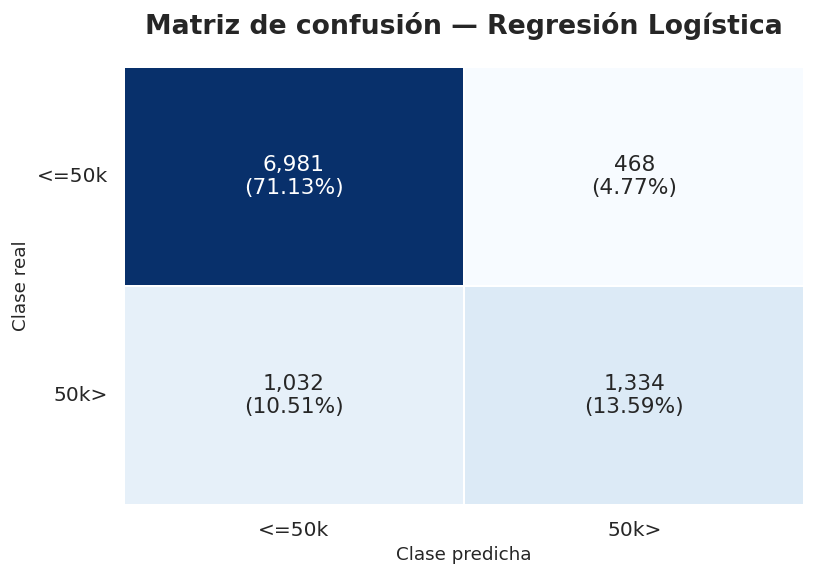

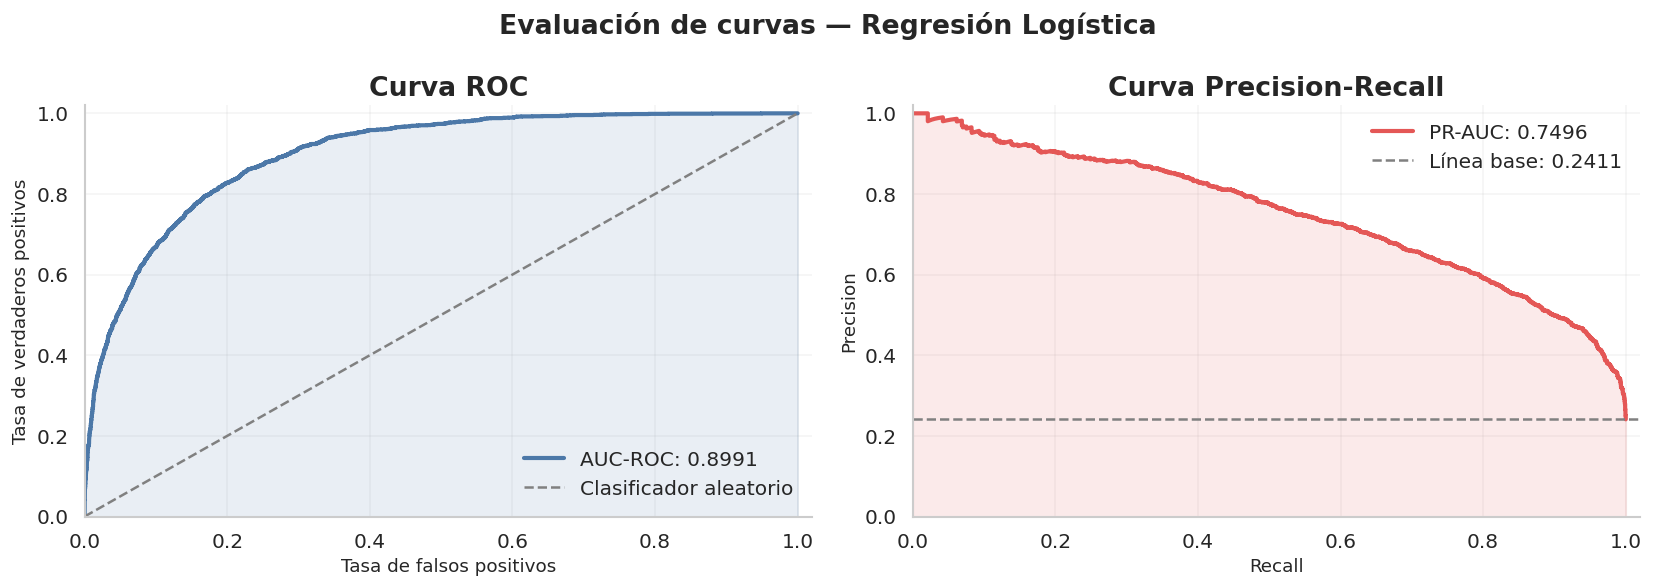

In [178]:
predRLog = modeloRLog.transform(testModelos)

resultadosRLog = evaluar_modelo(
    predRLog,
    "Regresión Logística"
)

graficar_matriz_confusion(
    predRLog,
    "Regresión Logística"
)

graficar_curvas(
    predRLog,
    "Regresión Logística",
    resultadosRLog
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Regresion Logistica</strong>

<p>
El modelo de Regresión Logística alcanza una exactitud (accuracy) del 84,72 % y un F1-Score ponderado de 0,8396. Asimismo, el AUC-ROC de 0,8991 evidencia una buena capacidad para distinguir entre individuos con ingresos superiores e inferiores a 50.000 dólares. Por su parte, el PR-AUC de 0,7496, considerablemente superior a la proporción de la clase positiva en el conjunto de evaluación (24,11 %), indica que el modelo logra identificar individuos con ingresos altos manteniendo una precisión relativamente elevada.

La matriz de confusión permite observar que el modelo clasifica correctamente 6.981 individuos con ingresos inferiores o iguales a 50K y 1.334 con ingresos superiores a 50K. Sin embargo, también presenta 1.032 falsos negativos y 468 falsos positivos, lo que evidencia una mayor dificultad para identificar correctamente a los individuos de la clase minoritaria. Aunque la mayoría de las predicciones positivas son correctas, el modelo deja sin identificar aproximadamente el 43,62 % de los individuos que realmente superan el umbral de ingresos.

En términos generales, la Regresión Logística constituye un modelo de referencia competitivo, con una buena capacidad discriminativa.
</p>
</div>


### **4.2 - Modelo Decision Tree**

Es un algoritmo de aprendizaje supervisado que realiza divisiones sucesivas de los datos mediante reglas de decisión, buscando maximizar la homogeneidad de las clases en cada nodo.

In [179]:
# Se instancia Modelo
DT = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    impurity="gini",
    maxDepth=8,
    maxBins=32,
    minInstancesPerNode=10,
    seed=42
)

# Se entrena Modelo
modeloDT = DT.fit(trainModelos)

Resultados: Decision Tree
----------------------------------------
AUC-ROC: 0.6886
PR-AUC: 0.3307
Accuracy: 0.8483
Precision: 0.8411
Recall: 0.8483
F1-Score: 0.8417


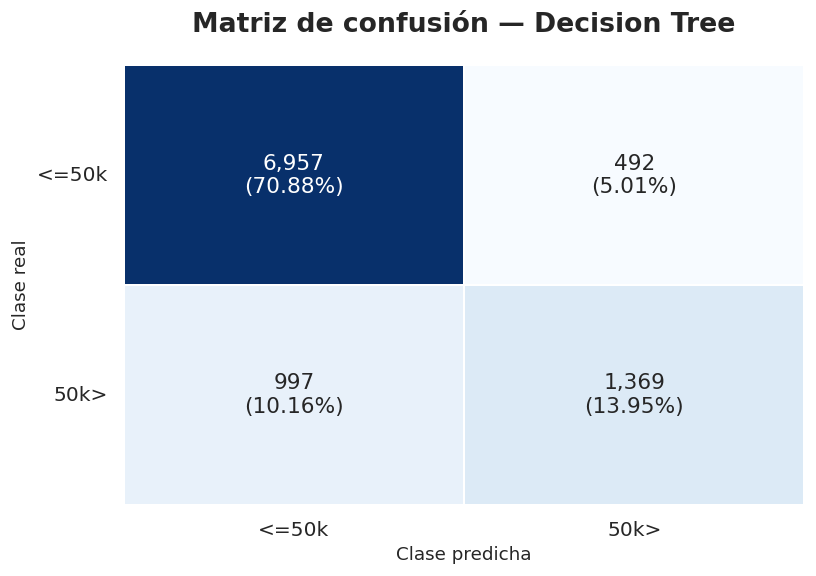

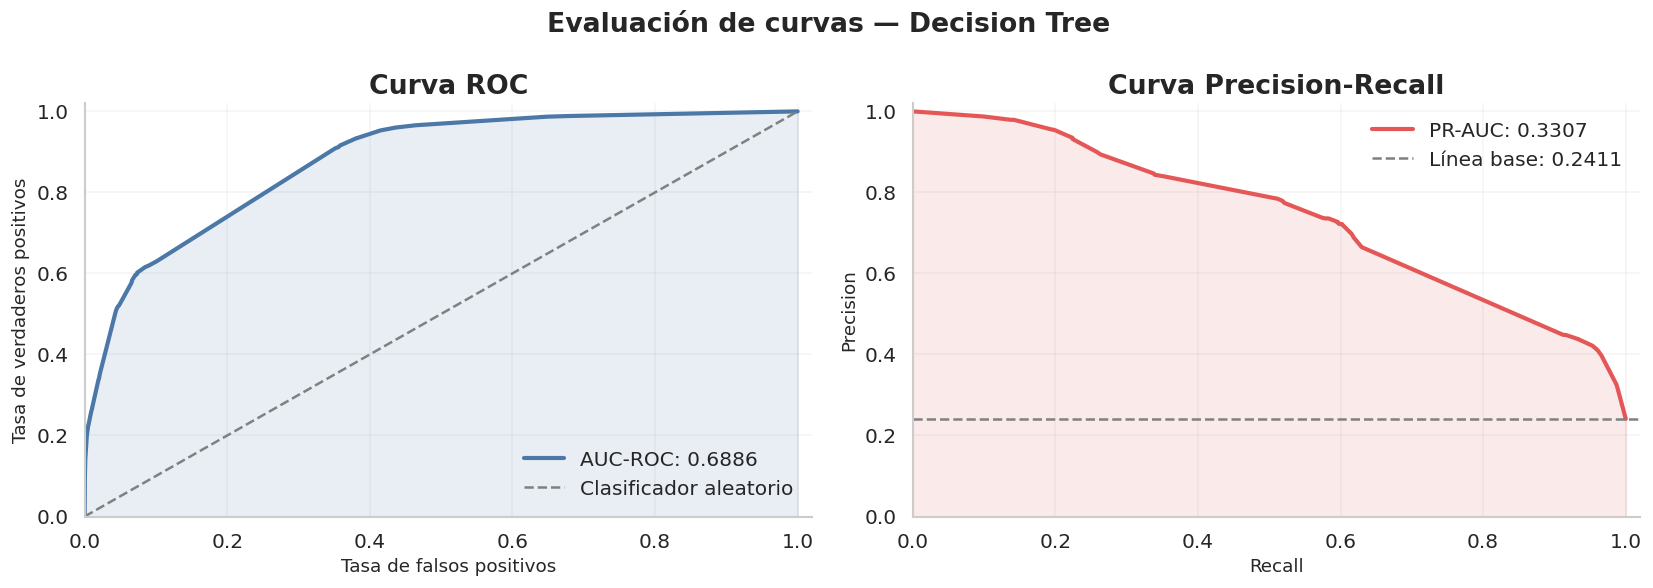

In [181]:
predDT = modeloDT.transform(testModelos)

resultadosArbolDecision = evaluar_modelo(
    predDT,
    "Decision Tree"
)

graficar_matriz_confusion(
    predDT,
    "Decision Tree"
)

graficar_curvas(
    predDT,
    "Decision Tree",
    resultadosArbolDecision
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Decision Tree</strong>

El modelo de Árbol de Decisión alcanza una exactitud del 84,83 % y un F1-Score ponderado de 0,8417, valores ligeramente superiores a los obtenidos mediante Regresión Logística. Sin embargo, las métricas basadas en curvas muestran diferencias importantes: el AUC-ROC de 0,6886 y el PR-AUC de 0,3307 son considerablemente inferiores a los del modelo anterior. Esto sugiere una menor capacidad para ordenar y distinguir las observaciones de ambas clases.

La matriz de confusión evidencia que el modelo clasifica correctamente 6.957 individuos con ingresos inferiores o iguales a 50K y 1.369 con ingresos superiores a 50K. Por otra parte, registra 997 falsos negativos y 492 falsos positivos. Por lo tanto, el modelo consigue identificar una proporción ligeramente mayor de individuos con ingresos altos, aunque a costa de incrementar los falsos positivos.

En conclusión, el Árbol de Decisión ofrece resultados competitivos en términos de exactitud y F1-Score, pero presenta una capacidad discriminativa inferior a la Regresión Logística, especialmente al considerar el PR-AUC en un conjunto de datos desbalanceado.
<p>

</p>
</div>


### **4.3 - Modelo Random Forest**

Es un algoritmo de aprendizaje por conjuntos (Ensemble Learning) basado en la técnica de Bagging, que combina múltiples árboles de decisión entrenados mediante muestras aleatorias de los datos y subconjuntos de características.

In [182]:
# Instancia Modelo
RF = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=10,
    maxBins=32,
    impurity="gini",
    featureSubsetStrategy="sqrt",
    minInstancesPerNode=5,
    subsamplingRate=1.0,
    seed=42
)
# Entrenamiento Modelo
modeloRF = RF.fit(trainModelos)

26/11/20 14:50:37 WARN DAGScheduler: Broadcasting large task binary with size 1100.1 KiB
26/11/20 14:50:41 WARN DAGScheduler: Broadcasting large task binary with size 1654.2 KiB
26/11/20 14:50:46 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB
26/11/20 14:50:52 WARN DAGScheduler: Broadcasting large task binary with size 3.3 MiB
26/11/20 14:50:58 WARN DAGScheduler: Broadcasting large task binary with size 4.5 MiB
                                                                                

26/11/20 14:51:24 WARN DAGScheduler: Broadcasting large task binary with size 1905.7 KiB
26/11/20 14:51:26 WARN DAGScheduler: Broadcasting large task binary with size 1905.7 KiB
26/11/20 14:51:27 WARN DAGScheduler: Broadcasting large task binary with size 1917.3 KiB
26/11/20 14:51:28 WARN DAGScheduler: Broadcasting large task binary with size 1917.3 KiB
26/11/20 14:51:29 WARN DAGScheduler: Broadcasting large task binary with size 1917.3 KiB
26/11/20 14:51:30 WARN DAGScheduler: Broadcasting large task binary with size 1917.3 KiB
26/11/20 14:51:31 WARN DAGScheduler: Broadcasting large task binary with size 1913.4 KiB


Resultados: Random Forest
----------------------------------------
AUC-ROC: 0.8993
PR-AUC: 0.7619
Accuracy: 0.8503
Precision: 0.8442
Recall: 0.8503
F1-Score: 0.8389


26/11/20 14:51:31 WARN DAGScheduler: Broadcasting large task binary with size 1909.1 KiB
                                                                                

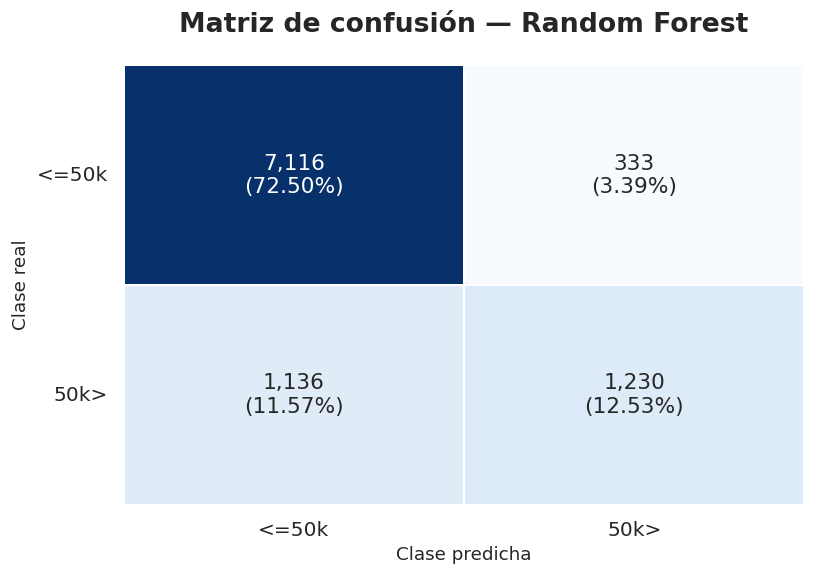

26/11/20 14:51:32 WARN DAGScheduler: Broadcasting large task binary with size 1901.7 KiB
                                                                                

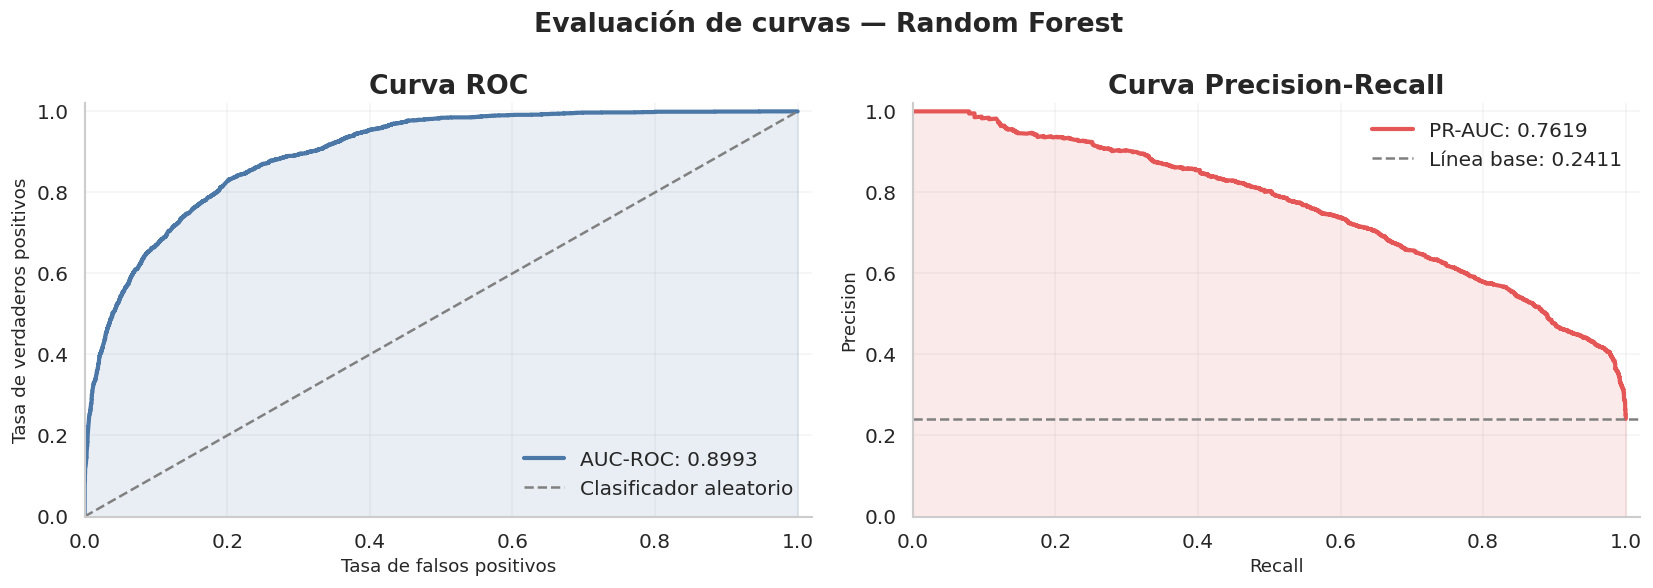

In [183]:
predRF = modeloRF.transform(testModelos)

resultadosRandomForest = evaluar_modelo(
    predRF,
    "Random Forest"
)

graficar_matriz_confusion(
    predRF,
    "Random Forest"
)

graficar_curvas(
    predRF,
    "Random Forest",
    resultadosRandomForest
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Random Forest</strong>

<p>
El modelo Random Forest alcanza una exactitud (accuracy) del 85,03 % y un F1-Score ponderado de 0,8389. Asimismo, obtiene un AUC-ROC de 0,8993 y un PR-AUC de 0,7619, lo que evidencia una buena capacidad para distinguir entre ambas clases. El modelo muestra una mejora considerable frente al Árbol de Decisión individual en las métricas basadas en curvas.

La matriz de confusión muestra que el modelo clasifica correctamente 7.116 individuos con ingresos inferiores o iguales a 50K y 1.230 con ingresos superiores a 50K. Sin embargo, presenta 1.136 falsos negativos y 333 falsos positivos. Aunque Random Forest reduce los falsos positivos respecto a los modelos anteriores, también incrementa los falsos negativos, identificando una proporción menor de individuos con ingresos superiores a 50K. E

En conclusión, Random Forest se posiciona como uno de los modelos más competitivos hasta el momento. No obstante, su menor sensibilidad frente a la clase positiva representa una limitación importante, particularmente en un conjunto de datos desbalanceado.
</p>
</div>


### **4.4 - Modelo Gradient-Boosted Trees (GBT)**

Es un algoritmo de aprendizaje por conjuntos basado en la técnica de Boosting, que construye árboles de decisión de manera secuencial. Cada nuevo árbol busca reducir los errores del modelo acumulado.

In [184]:
# Se instancia Modelo
GBT = GBTClassifier(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    maxDepth=5,
    maxBins=32,
    stepSize=0.1,
    subsamplingRate=0.8,
    minInstancesPerNode=5,
    lossType="logistic",
    seed=42
)


# Se entrena Modelo
modeloGBT = GBT.fit(trainModelos)

Resultados: Gradient-Boosted Trees
----------------------------------------
AUC-ROC: 0.9135
PR-AUC: 0.7910
Accuracy: 0.8603
Precision: 0.8545
Recall: 0.8603
F1-Score: 0.8548


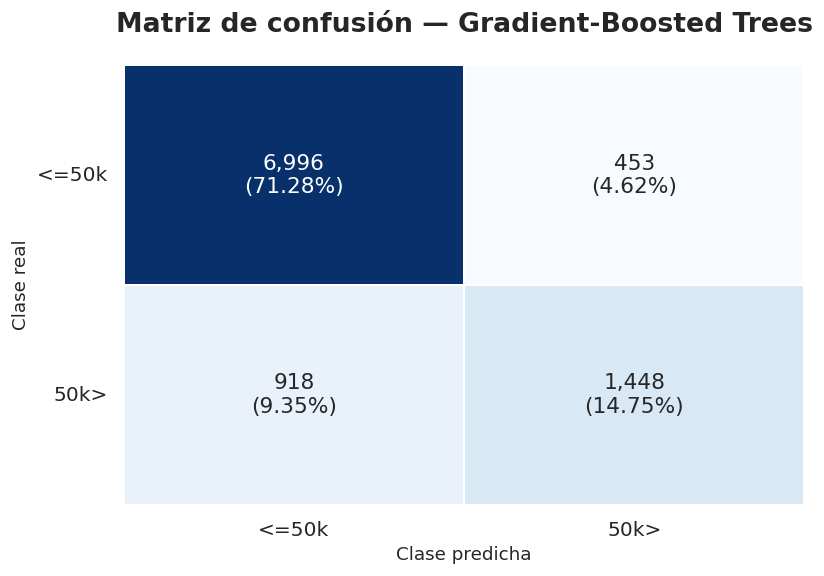

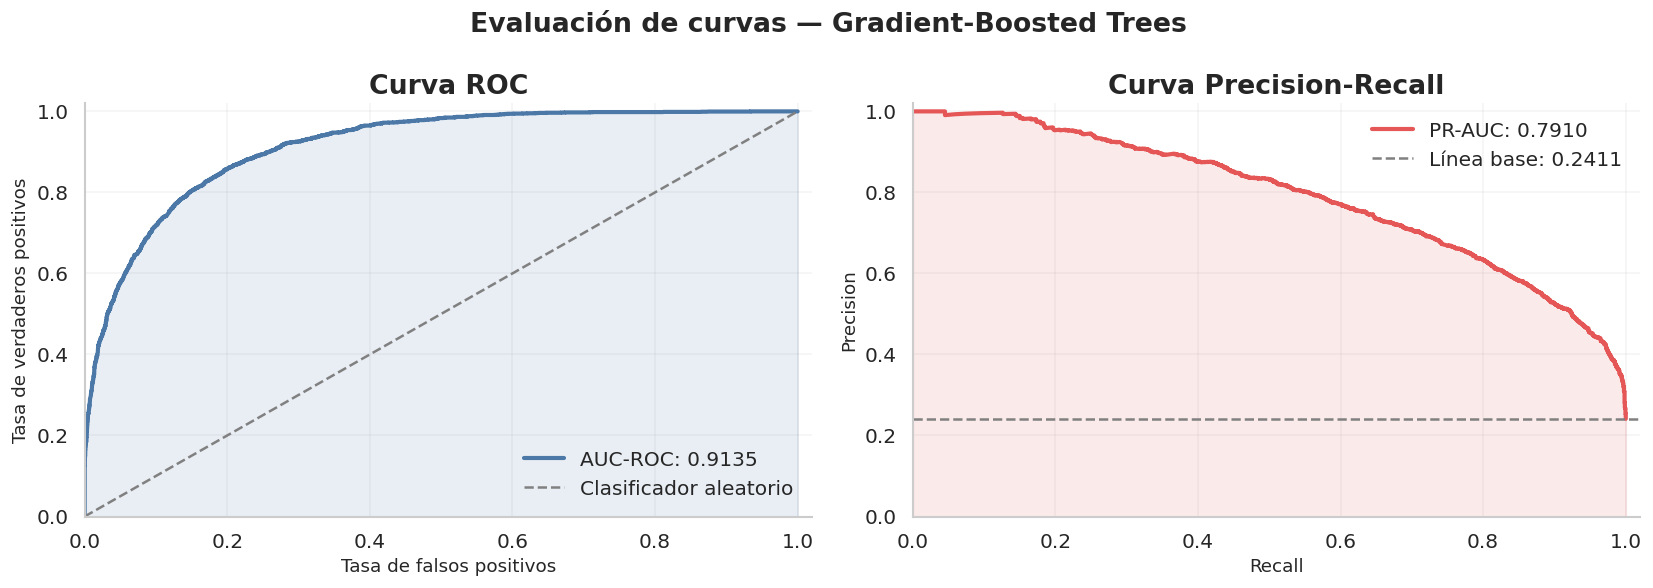

In [185]:
predGBT = modeloGBT.transform(testModelos)

resultadosGBT = evaluar_modelo(
    predGBT,
    "Gradient-Boosted Trees"
)

graficar_matriz_confusion(
    predGBT,
    "Gradient-Boosted Trees"
)

graficar_curvas(
    predGBT,
    "Gradient-Boosted Trees",
    resultadosGBT
)

<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">

<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Gradient-Boosted Trees</strong>
    
El modelo Gradient-Boosted Trees alcanza una exactitud  del 86,03 % y un F1-Score ponderado de 0,8548. Asimismo, obtiene un AUC-ROC de 0,9135 y un PR-AUC de 0,7910, superando los resultados del resto de modelos. Estos valores evidencian una mayor capacidad para diferenciar entre individuos con ingresos superiores e inferiores o iguales a 50K, incluso considerando el desbalance existente entre ambas clases.

La matriz de confusión muestra que el modelo clasifica correctamente 6.996 individuos con ingresos inferiores o iguales a 50K y 1.448 con ingresos superiores a 50K. Por otra parte, registra 453 falsos positivos y 918 falsos negativos. El AUC-ROC de 0,9135 indica una elevada capacidad discriminativa, mientras que el PR-AUC de 0,7910 demuestra un mejor equilibrio entre precisión y sensibilidad a lo largo de distintos umbrales de clasificación. Este último resultado es especialmente relevante debido al desbalance de clases.

En conclusión, el rendimiento del modelo sugiere que la combinación secuencial de árboles permite capturar relaciones complejas entre las variables predictoras. No obstante, todavía clasifica incorrectamente una proporción considerable de la clase positiva.
<p>

</p>
</div>

### **4.5 - Multilayer Perceptron (MLP)**

Es un algoritmo de aprendizaje supervisado basado en redes neuronales artificiales, compuesto por una capa de entrada, una o varias capas ocultas y una capa de salida. Permite capturar relaciones no lineales y complejas entre las características de los pacientes y la variable objetivo.

In [187]:
## Definir tamaño capa de entrada dado el numero de caracteristicas

numCaracteristicas = (
    trainModelos.first()["features_scaled"].size
)

capas = [
    numCaracteristicas,
    64,
    32,
    2
]

print(f"Arquitectura de la red: {capas}")

Arquitectura de la red: [122, 64, 32, 2]


In [188]:
## Se instancia modelo

MLP = MultilayerPerceptronClassifier(
    featuresCol="features_scaled",
    labelCol="label",
    layers=capas,
    maxIter=200,
    blockSize=128,
    solver="l-bfgs",
    tol=1e-6,
    seed=42
)



## Se entrena modelo

modeloMLP = MLP.fit(trainModelos)

Resultados: Multilayer Perceptron
----------------------------------------
AUC-ROC: 0.8780
PR-AUC: 0.7149
Accuracy: 0.8428
Precision: 0.8369
Recall: 0.8428
F1-Score: 0.8386


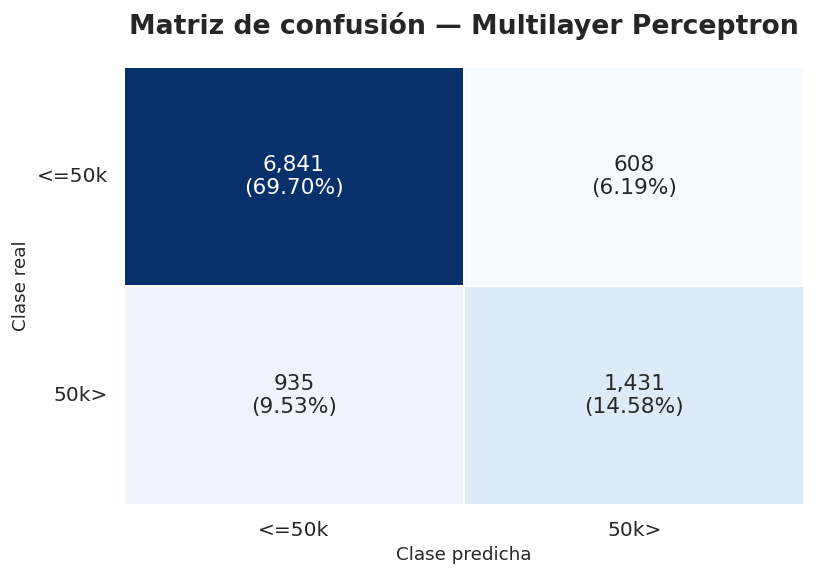

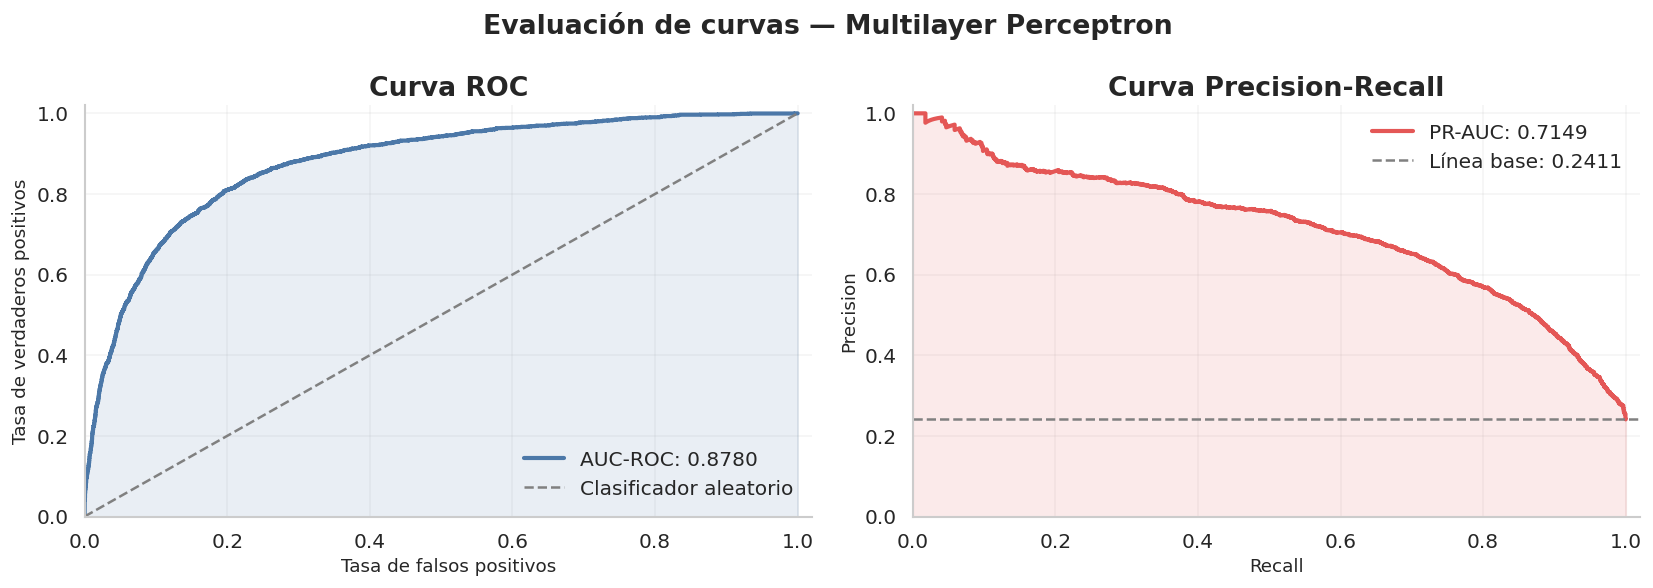

In [189]:
predMLP = modeloMLP.transform(testModelos)


resultadosMLP = evaluar_modelo(
    predMLP,
    "Multilayer Perceptron"
)

graficar_matriz_confusion(
    predMLP,
    "Multilayer Perceptron"
)

graficar_curvas(
    predMLP,
    "Multilayer Perceptron",
    resultadosMLP
)

<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">

<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis MultiLayer Perceptron</strong>

El modelo Multilayer Perceptron alcanza una exactitud del 84,28 % y un F1-Score ponderado de 0,8386. Asimismo, obtiene un AUC-ROC de 0,8780 y un PR-AUC de 0,7149.

La matriz de confusión muestra que el modelo clasifica correctamente 6.841 individuos con ingresos inferiores o iguales a 50K y 1.431 individuos con ingresos superiores a 50K. Sin embargo, registra 608 falsos positivos y 935 falsos negativos. Esto muestra que presenta dificultades para reconocer a todos los integrantes de la categoría con ingresos elevados.

En conclusión, Multilayer Perceptron presenta un rendimiento competitivo, pero no supera a los modelos más destacados del estudio. Aunque las redes neuronales permiten representar relaciones no lineales complejas, su rendimiento depende considerablemente de factores como la arquitectura, el escalado de las variables y la configuración del entrenamiento.
<p>

</p>
</div>

#### **Se almacenan resultados para analisis general**

In [191]:
resultadosModelos = pd.DataFrame([
    resultadosRLog,
    resultadosArbolDecision,
    resultadosRandomForest,
    resultadosGBT,
    resultadosMLP
])

modelos = {
    "Regresión Logística": modeloRLog,
    "Decision Tree": modeloDT,
    "Random Forest": modeloRF,
    "Gradient-Boosted Trees": modeloGBT,
    "Multilayer Perceptron": modeloMLP
}

prediccionesModelos = {
    "Regresión Logística": predRLog,
    "Decision Tree": predDT,
    "Random Forest": predRF,
    "Gradient-Boosted Trees": predGBT,
    "Multilayer Perceptron": predMLP
}


### **4.6 - Analisis General Modelos**

In [193]:
resultadosComparativos = resultadosModelos.copy()

for nombre, predicciones in prediccionesModelos.items():

    conteos = {
        (int(fila["label"]), int(fila["prediction"])): fila["count"]
        for fila in predicciones
        .groupBy("label", "prediction")
        .count()
        .collect()
    }

    VN = conteos.get((0, 0), 0)
    FP = conteos.get((0, 1), 0)
    FN = conteos.get((1, 0), 0)
    VP = conteos.get((1, 1), 0)


    filtro = resultadosComparativos["Modelo"] == nombre

    resultadosComparativos.loc[filtro, "Verdaderos positivos"] = VP
    resultadosComparativos.loc[filtro, "Verdaderos negativos"] = VN
    resultadosComparativos.loc[filtro, "Falsos positivos"] = FP
    resultadosComparativos.loc[filtro, "Falsos negativos"] = FN


columnasConteos = [
    "Verdaderos positivos",
    "Verdaderos negativos",
    "Falsos positivos",
    "Falsos negativos"
]

resultadosComparativos[columnasConteos] = (
    resultadosComparativos[columnasConteos].astype(int)
)

tablaComparativa = resultadosComparativos.set_index("Modelo").T

metricasMaximizar = [
    "AUC-ROC",
    "PR-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Verdaderos positivos",
    "Verdaderos negativos"
]

metricasMinimizar = [
    "Falsos positivos",
    "Falsos negativos"
]

def resaltar_resultados(fila):

    if fila.max() == fila.min():
        return [""] * len(fila)

    if fila.name in metricasMaximizar:
        mejor = fila.max()
        peor = fila.min()
    elif fila.name in metricasMinimizar:
        mejor = fila.min()
        peor = fila.max()
    else:
        return [""] * len(fila)

    return [
        "background-color: #DCFCE7; color: #166534; font-weight: bold"
        if valor == mejor else
        "background-color: #FEE2E2; color: #991B1B"
        if valor == peor else ""
        for valor in fila
    ]

tablaEstilizada = (
    tablaComparativa.style
    .apply(resaltar_resultados, axis=1)
    .format("{:.4f}")
    .format("{:.0f}", subset=pd.IndexSlice[columnasConteos, :])
    .set_caption("Comparación del rendimiento de los modelos")
    .set_properties(**{
        "text-align": "center",
        "padding": "10px"
    })
)

display(tablaEstilizada)

26/11/20 15:00:40 WARN DAGScheduler: Broadcasting large task binary with size 1913.4 KiB
26/11/20 15:00:41 WARN DAGScheduler: Broadcasting large task binary with size 1909.1 KiB
                                                                                

Modelo,Regresión Logística,Decision Tree,Random Forest,Gradient-Boosted Trees,Multilayer Perceptron
AUC-ROC,0.8991,0.6886,0.8993,0.9135,0.8780
PR-AUC,0.7496,0.3307,0.7619,0.7910,0.7149
Accuracy,0.8472,0.8483,0.8503,0.8603,0.8428
Precision,0.8396,0.8411,0.8442,0.8545,0.8369
Recall,0.8472,0.8483,0.8503,0.8603,0.8428
F1-Score,0.8396,0.8417,0.8389,0.8548,0.8386
Verdaderos positivos,1334,1369,1230,1448,1431
Verdaderos negativos,6981,6957,7116,6996,6841
Falsos positivos,468,492,333,453,608
Falsos negativos,1032,997,1136,918,935


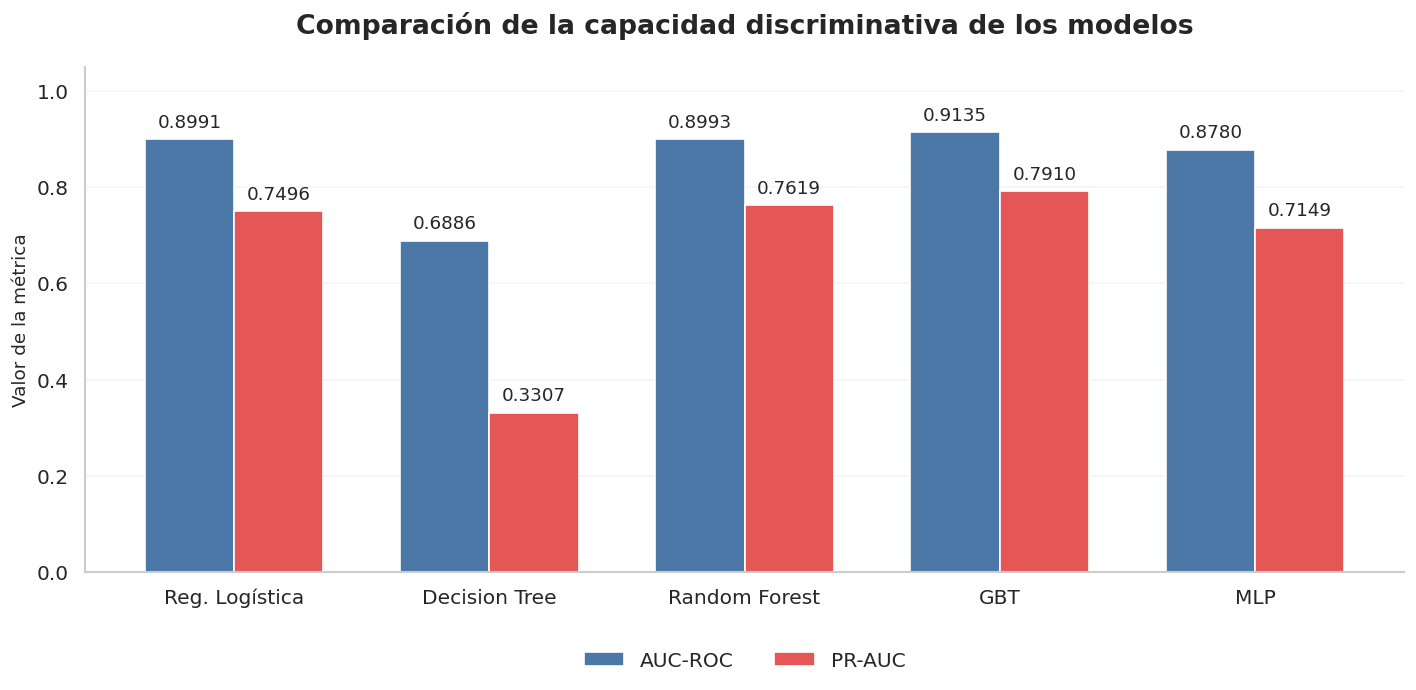

In [194]:

nombresCortos = {
    "Regresión Logística": "Reg. Logística",
    "Decision Tree": "Decision Tree",
    "Random Forest": "Random Forest",
    "Gradient-Boosted Trees": "GBT",
    "Multilayer Perceptron": "MLP"
    
}
fig, ax = plt.subplots(figsize=(12, 6))

posiciones = np.arange(len(resultadosComparativos))
ancho = 0.35

barrasROC = ax.bar(
    posiciones - ancho / 2,
    resultadosComparativos["AUC-ROC"],
    width=ancho,
    color="#4C78A8",
    label="AUC-ROC"
)

barrasPR = ax.bar(
    posiciones + ancho / 2,
    resultadosComparativos["PR-AUC"],
    width=ancho,
    color="#E45756",
    label="PR-AUC"
)

ax.bar_label(
    barrasROC,
    fmt="%.4f",
    padding=5,
    fontsize=11
)

ax.bar_label(
    barrasPR,
    fmt="%.4f",
    padding=5,
    fontsize=11
)

ax.set_xticks(posiciones)

ax.set_xticklabels([
    nombresCortos[nombre]
    for nombre in resultadosComparativos["Modelo"]
])

ax.set_title(
    "Comparación de la capacidad discriminativa de los modelos",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1.05)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2
)

ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">

<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis General Modelos</strong>
    
El análisis comparativo de los cinco modelos evidencia que Gradient-Boosted Trees (GBT) presenta el mejor rendimiento general, alcanzando un AUC-ROC de 0,9135, un PR-AUC de 0,7910 y una exactitud del 86,03 %. Por su parte, Random Forest y Regresión Logística muestran resultados competitivos, con valores de AUC-ROC cercanos a 0,90. En contraste, Decision Tree presenta la menor capacidad discriminativa, especialmente en PR-AUC (0,3307), mientras que Multilayer Perceptron obtiene un rendimiento intermedio, sin superar a los modelos más destacados.

Al analizar las matrices de confusión, GBT también consigue la mayor cantidad de verdaderos positivos (1.448) y la menor cantidad de falsos negativos (918), lo que demuestra una mayor capacidad para identificar individuos con ingresos superiores a 50K. Sin embargo, Random Forest registra la menor cantidad de falsos positivos (333) y la mayor cantidad de verdaderos negativos (7.116), por lo que resulta más conservador al clasificar individuos dentro de la categoría de ingresos elevados. Estas diferencias evidencian que la selección del modelo depende también del tipo de error que se busque minimizar.

En este sentido, GBT ofrece el mejor equilibrio entre rendimiento general e identificación de la clase minoritaria, posicionándose como la alternativa más adecuada para el problema estudiado.
<p>

</p>
</div>

## **Conclusiones**

<div style="padding: 10px 15px; border-left: 3px solid #555;">

El análisis exploratorio permitió identificar relaciones relevantes entre las características de los individuos y sus ingresos. Variables como la edad, las horas trabajadas, el nivel educativo, la ocupación y la relación familiar mostraron diferencias importantes entre las categorías de ingresos. Asimismo, se identificó un desbalance en la variable objetivo, donde aproximadamente el 76 % de los individuos pertenece a la clase de ingresos inferiores o iguales a 50K. Este hallazgo permitió comprender que la exactitud por sí sola no resulta suficiente para evaluar los modelos y que es necesario considerar métricas adicionales que reflejen su capacidad para identificar correctamente la clase minoritaria.

La comparación de los cinco algoritmos evidenció diferencias significativas en su capacidad predictiva. Gradient-Boosted Trees obtuvo el mejor rendimiento general, con un AUC-ROC de 0,9135, un PR-AUC de 0,7910 y una exactitud del 86,03 %, además de registrar la menor cantidad de falsos negativos. Por otra parte, Random Forest destacó por minimizar los falsos positivos, mientras que Regresión Logística demostró que un modelo relativamente sencillo puede alcanzar resultados competitivos. En contraste, Decision Tree y Multilayer Perceptron presentaron un rendimiento inferior en términos de capacidad discriminativa.

Finalmente, a pesar de que Gradient-Boosted Trees represente la alternativa más adecuada entre las configuraciones evaluadas, todavía existen oportunidades de mejora mediante el ajuste de hiperparámetros y de los umbrales de decisión. 

</div>

In [ ]:
sparkRamirez.stop()